# Hallucination-Penalty RL-RAG Bandit — Revised All-in-One Research Notebook

This notebook is intended to become the **single executable source of truth** for the research paper:

> **Reward-Driven Hallucination Control in Retrieval-Augmented Generation via Bandit Learning**

It consolidates the functionality previously spread across `config.py`, `utils/`, `rag/`, `llm/`, `scoring/`, `rl/`, `experiments/`, and the earlier fixed notebook.

## Author's current paper-edit status

The author has already manually rectified **Points 1–5**, **except Point 2A**, from the prior review.  
**Point 2A and Point 6 onward have not yet been manually reviewed/rectified in the paper.**

This notebook does **not** assume those remaining paper edits are complete. It focuses on creating a clean, reproducible implementation that the revised paper can accurately describe.

## Major implementation corrections included

- Fresh, isolated experiment runs; no accidental concatenation of old sessions.
- No loading of an unrelated historical bandit state for a new scientific run.
- The bandit chooses an action **before** generation; only the selected arm is observed during training.
- API failures are never converted into hallucination rewards.
- Correct epsilon decay tracking.
- Single-run plotting only (fixes the pending Point 2A code issue).
- Canonical citation format across prompts, contexts, and evaluation.
- Sentence-aware chunking.
- Strict abstention detection instead of substring reward bypass.
- Corpus-size diagnostics and optional strict final-experiment checks.
- Deterministic train/validation/test split.
- Fixed-strategy baselines A0–A4.
- Uniform-random baseline.
- Generate-all + score-max baseline (evaluated separately, not used for bandit training).
- Citation-enforced RAG baseline with citation-validity metrics.
- Multiple-seed experiment support.
- Bootstrap confidence intervals and paired comparisons.
- Threshold calibration support from human annotations.
- Optional stronger NLI factual-support evaluator.
- Reproducibility metadata for every run.
- Paper-ready CSV summaries and figures.

> **Important:** The current three-document pilot corpus is still too small for a strong final retrieval experiment. This notebook can run in pilot mode, but `FINAL_EXPERIMENT_MODE=True` deliberately refuses to run if the indexed corpus is not larger than the retrieval depth.

## 1. Install dependencies

Run this once in a fresh Google Colab runtime.

In [277]:
!pip -q install google-genai faiss-cpu sentence-transformers pypdf python-dotenv pandas numpy matplotlib scikit-learn nltk tqdm

## 2. Mount Google Drive and import libraries

In [278]:
from google.colab import drive
drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [279]:
from __future__ import annotations

import csv
import hashlib
import json
import math
import os
import random
import re
import time
import warnings
from dataclasses import dataclass, asdict
from datetime import datetime, timezone
from pathlib import Path
from typing import Any, Dict, Iterable, List, Optional, Sequence, Tuple

import faiss
import matplotlib.pyplot as plt
import nltk
import numpy as np
import pandas as pd
import pypdf

from dotenv import load_dotenv
from IPython.display import display, Markdown, Image as IPyImage
from sentence_transformers import SentenceTransformer
from sklearn.model_selection import train_test_split
from tqdm.auto import tqdm

nltk.download("punkt", quiet=True)
try:
    nltk.download("punkt_tab", quiet=True)
except Exception:
    pass

print("Imports ready.")

Imports ready.


## 3. Configuration

For the existing project, the default repository path is:

`/content/drive/MyDrive/hallucination-penalty-rl-rag-bandit`

### Recommended workflow

- Keep `FINAL_EXPERIMENT_MODE = False` while debugging.
- Set it to `True` only after adding a substantially larger evaluation corpus.
- Keep destructive/rebuild/training switches `False` until you intentionally want to run them.

In [315]:
# =========================
# PATHS
# =========================

REPO_ROOT = Path("/content/drive/MyDrive/hallucination-penalty-rl-rag-bandit")
DATA_DIR = REPO_ROOT / "data"
SAMPLE_DOCS_DIR = DATA_DIR / "sample_docs"
QUESTION_SET = DATA_DIR / "questions.jsonl"

OUTPUTS_DIR = REPO_ROOT / "outputs"
FINAL_RUNS_DIR = OUTPUTS_DIR / "final_runs"
BASELINE_RUNS_DIR = OUTPUTS_DIR / "baseline_runs"
ANNOTATION_DIR = OUTPUTS_DIR / "human_annotation"

CHUNKS_JSONL = OUTPUTS_DIR / "chunks.jsonl"
FAISS_INDEX = OUTPUTS_DIR / "faiss.index"
METADATA_JSON = OUTPUTS_DIR / "chunk_metadata.json"

# =========================
# MODELS
# =========================

DEFAULT_EMBED_MODEL = "sentence-transformers/all-MiniLM-L6-v2"
DEFAULT_GEMINI_MODEL = "gemini-2.5-flash"

# Optional stronger evaluator. Large download; disabled by default.
ENABLE_NLI_EVALUATOR = False
NLI_MODEL_NAME = "facebook/bart-large-mnli"

# =========================
# RETRIEVAL / CHUNKING
# =========================

CHUNK_SIZE_WORDS = 220
CHUNK_OVERLAP_WORDS = 40
DEFAULT_TOP_K = 5

# In final mode, the notebook refuses to treat a corpus with <= top_k chunks
# as a meaningful retrieval experiment.
FINAL_EXPERIMENT_MODE = True

# =========================
# REWARD
# =========================

DEFAULT_SENT_SIM_THRESHOLD = 0.50
ABSTENTION_TEXT = "Not in context"

# reward_mode:
# "semantic_proxy" = paper's original support-ratio reward, with strict abstention handling.
# "answerability_aware" = additionally rewards correct abstention / penalizes false abstention
#                         when answerability labels exist.
DEFAULT_REWARD_MODE = "semantic_proxy"

# =========================
# BANDIT
# =========================

ACTIONS = ["A0", "A1", "A2", "A3", "A4"]
DEFAULT_EPSILON = 0.20
EPSILON_DECAY = 0.99
MIN_EPSILON = 0.01

ACTION_TEMPERATURES = {
    "A0": 0.0,
    "A1": 0.2,
    "A2": 0.0,
    "A3": 0.2,
    "A4": 0.9,
}

# Controlled-temperature ablation
CONTROLLED_TEMPERATURE = 0.2

# =========================
# EXPERIMENT SWITCHES
# =========================
RUN_INGEST = False
RUN_BUILD_INDEX = False

RUN_SINGLE_TRAINING = False
RUN_MULTI_SEED_TRAINING = False

RUN_BASELINES = False

RUN_CONTROLLED_TEMP_ABLATION = False
RUN_THRESHOLD_CALIBRATION = False


TRAIN_EPISODES = 200

MASTER_SEED = 42

MULTI_SEEDS = [
    11,
    22,
    33,
    44,
    55
]

# =========================
# CREATE DIRECTORIES
# =========================

for path in [
    DATA_DIR,
    SAMPLE_DOCS_DIR,
    OUTPUTS_DIR,
    FINAL_RUNS_DIR,
    BASELINE_RUNS_DIR,
    ANNOTATION_DIR,
]:
    path.mkdir(parents=True, exist_ok=True)

print("Repository:", REPO_ROOT)

Repository: /content/drive/MyDrive/hallucination-penalty-rl-rag-bandit


## 4. Environment and reproducibility utilities

The API key is loaded from either:

1. `.env` in the repository root, or
2. Google Colab Secrets (`GOOGLE_API_KEY`).

No key is printed in full.

In [281]:
def utc_now_iso() -> str:
    return datetime.now(timezone.utc).isoformat()


def set_global_seed(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)


def load_environment() -> Dict[str, Any]:
    env_path = REPO_ROOT / ".env"
    loaded_dotenv = False

    if env_path.exists():
        loaded_dotenv = load_dotenv(env_path)

    key = os.getenv("GOOGLE_API_KEY")

    if not key:
        try:
            from google.colab import userdata
            key = userdata.get("GOOGLE_API_KEY")
            if key:
                os.environ["GOOGLE_API_KEY"] = key
        except Exception:
            pass

    return {
        "env_path": str(env_path),
        "dotenv_loaded": bool(loaded_dotenv),
        "gemini_key_present": bool(os.getenv("GOOGLE_API_KEY")),
    }


def file_sha256(path: Path) -> Optional[str]:
    if not path.exists() or not path.is_file():
        return None

    h = hashlib.sha256()
    with open(path, "rb") as f:
        for block in iter(lambda: f.read(1024 * 1024), b""):
            h.update(block)
    return h.hexdigest()


env_status = load_environment()
display(pd.DataFrame([env_status]))

,env_path,dotenv_loaded,gemini_key_present
0,/content/drive/MyDrive/hallucination-penalty-r...,True,True


## 5. JSON / JSONL / text / PDF helpers

In [282]:
def safe_read_json(path: Path, default=None):
    if not path.exists():
        return default
    with open(path, "r", encoding="utf-8") as f:
        return json.load(f)


def safe_write_json(path: Path, obj: Any) -> None:
    path.parent.mkdir(parents=True, exist_ok=True)
    with open(path, "w", encoding="utf-8") as f:
        json.dump(obj, f, indent=2, ensure_ascii=False)


def read_jsonl(path: Path) -> List[Dict[str, Any]]:
    if not path.exists():
        return []

    rows = []
    with open(path, "r", encoding="utf-8") as f:
        for line in f:
            line = line.strip()
            if line:
                rows.append(json.loads(line))
    return rows


def write_jsonl(path: Path, rows: Iterable[Dict[str, Any]]) -> None:
    path.parent.mkdir(parents=True, exist_ok=True)
    with open(path, "w", encoding="utf-8") as f:
        for row in rows:
            f.write(json.dumps(row, ensure_ascii=False) + "\n")


def read_text_file(path: Path) -> str:
    return path.read_text(encoding="utf-8", errors="ignore")


def extract_text_from_pdf(path: Path) -> str:
    reader = pypdf.PdfReader(str(path))
    parts = []

    for page in reader.pages:
        text = page.extract_text() or ""
        if text.strip():
            parts.append(text)

    return "\n".join(parts)


def normalize_text(text: str) -> str:
    text = text.replace("\x00", " ")
    text = re.sub(r"\s+", " ", text)
    return text.strip()


def list_documents(data_dir: Path = DATA_DIR) -> List[Path]:
    supported = {".txt", ".md", ".pdf"}
    docs = []

    for path in data_dir.rglob("*"):
        if not path.is_file():
            continue
        if path == QUESTION_SET:
            continue
        if path.suffix.lower() in supported:
            docs.append(path)

    return sorted(docs)


print("I/O helpers ready.")

I/O helpers ready.


## 6. Sentence-aware text processing and chunking

This fixes the earlier mismatch where the paper described sentences being preserved at chunk boundaries while the implementation actually used raw word windows.

The implementation below builds chunks from complete sentences whenever possible, while still enforcing an approximate word budget and sentence-level overlap.

In [283]:
def sentence_split(text: str) -> List[str]:
    text = (text or "").strip()
    if not text:
        return []

    try:
        sentences = nltk.sent_tokenize(text)
    except Exception:
        sentences = re.split(r"(?<=[.!?])\s+", text)

    return [s.strip() for s in sentences if s.strip()]


def chunk_text_sentence_aware(
    text: str,
    max_words: int = CHUNK_SIZE_WORDS,
    overlap_words: int = CHUNK_OVERLAP_WORDS,
) -> List[str]:
    sentences = sentence_split(normalize_text(text))

    if not sentences:
        return []

    chunks: List[str] = []
    current: List[str] = []
    current_words = 0

    for sentence in sentences:
        sentence_words = len(sentence.split())

        # If a single sentence is longer than the target size, keep it intact.
        if current and current_words + sentence_words > max_words:
            chunk = " ".join(current).strip()
            chunks.append(chunk)

            # Build sentence-level overlap from the end of the previous chunk.
            overlap_sentences: List[str] = []
            overlap_count = 0

            for previous_sentence in reversed(current):
                overlap_sentences.insert(0, previous_sentence)
                overlap_count += len(previous_sentence.split())

                if overlap_count >= overlap_words:
                    break

            current = overlap_sentences
            current_words = sum(len(s.split()) for s in current)

        current.append(sentence)
        current_words += sentence_words

    if current:
        final_chunk = " ".join(current).strip()
        if not chunks or final_chunk != chunks[-1]:
            chunks.append(final_chunk)

    return chunks


print("Sentence-aware chunker ready.")

Sentence-aware chunker ready.


In [284]:
# ============================================================
# BUILD A LARGE WIKIPEDIA-BASED CORPUS
# ROBUST VERSION WITH RATE-LIMIT HANDLING
# ============================================================

import requests
import time
import re
import random
from pathlib import Path
from urllib.parse import quote


# ============================================================
# CONFIGURATION
# ============================================================

WIKIPEDIA_CORPUS_DIR = (
    DATA_DIR
    / "wikipedia_corpus"
)

WIKIPEDIA_CORPUS_DIR.mkdir(
    parents=True,
    exist_ok=True
)


WIKIPEDIA_API = (
    "https://en.wikipedia.org/w/api.php"
)


# IMPORTANT:
# Replace the email below with your real email address.
# Wikimedia recommends a descriptive User-Agent with contact information.
HEADERS = {
    "User-Agent": (
        "HallucinationPenaltyRAGResearch/1.0 "
        "(academic research; contact: shauryaaggarwal987@gmail.com)"
    ),
    "Accept-Encoding": "gzip"
}


# Use one persistent HTTP session.
SESSION = requests.Session()

SESSION.headers.update(
    HEADERS
)


# Categories related to the scope of the paper.
SEED_CATEGORIES = [
    "Artificial intelligence",
    "Machine learning",
    "Natural language processing",
    "Information retrieval",
    "Reinforcement learning",
    "Databases",
    "Computer science",
]


TARGET_DOCUMENTS = 300

MIN_WORDS_PER_ARTICLE = 300


# Smaller batches reduce the load per request.
ARTICLE_BATCH_SIZE = 10


# Normal pause between successful requests.
REQUEST_DELAY_SECONDS = 1.5


# Maximum number of retries after 429 / 503 / maxlag.
MAX_RETRIES = 8


# ============================================================
# HELPERS
# ============================================================

def safe_filename(title):

    name = re.sub(
        r"[^A-Za-z0-9_-]+",
        "_",
        title
    )

    return (
        name.strip("_")[:150]
        + ".txt"
    )


def wikipedia_request(
    params,
    max_retries=MAX_RETRIES
):
    """
    Send a Wikipedia API request with automatic handling for:

    - HTTP 429: Too Many Requests
    - HTTP 503: Service Unavailable
    - MediaWiki ratelimited errors
    - MediaWiki maxlag errors

    Uses Retry-After when supplied, otherwise exponential backoff.
    """

    params = dict(
        params
    )

    # Recommended for non-interactive/bulk API jobs.
    params["maxlag"] = 5


    for attempt in range(
        max_retries
    ):

        try:

            response = SESSION.get(
                WIKIPEDIA_API,
                params=params,
                timeout=60
            )


            # ====================================================
            # HANDLE HTTP 429 / 503
            # ====================================================

            if response.status_code in (
                429,
                503
            ):

                retry_after = (
                    response
                    .headers
                    .get(
                        "Retry-After"
                    )
                )


                if retry_after:

                    try:

                        wait_time = float(
                            retry_after
                        )

                    except ValueError:

                        wait_time = (
                            5
                            * (
                                2 ** attempt
                            )
                        )

                else:

                    # Exponential backoff:
                    #
                    # 5 sec
                    # 10 sec
                    # 20 sec
                    # 40 sec
                    # ...
                    wait_time = (
                        5
                        * (
                            2 ** attempt
                        )
                    )


                # Avoid multiple clients retrying
                # at exactly the same moment.
                jitter = random.uniform(
                    0,
                    2
                )

                wait_time += jitter


                # Do not allow one sleep
                # to become excessively long.
                wait_time = min(
                    wait_time,
                    180
                )


                print(
                    f"\nWikipedia returned "
                    f"HTTP {response.status_code}."
                )

                print(
                    f"Waiting "
                    f"{wait_time:.1f} seconds "
                    f"before retry "
                    f"{attempt + 1}/"
                    f"{max_retries}..."
                )


                time.sleep(
                    wait_time
                )

                continue


            # Raise other HTTP errors.
            response.raise_for_status()


            data = response.json()


            # ====================================================
            # HANDLE MEDIAWIKI-LEVEL ERRORS
            # ====================================================

            api_error = data.get(
                "error"
            )


            if api_error:

                error_code = (
                    api_error
                    .get(
                        "code",
                        ""
                    )
                )


                if error_code in (
                    "ratelimited",
                    "maxlag"
                ):

                    wait_time = min(
                        5
                        * (
                            2 ** attempt
                        )
                        + random.uniform(
                            0,
                            2
                        ),
                        180
                    )


                    print(
                        f"\nWikipedia API returned "
                        f"'{error_code}'."
                    )

                    print(
                        f"Waiting "
                        f"{wait_time:.1f} seconds "
                        f"before retry..."
                    )


                    time.sleep(
                        wait_time
                    )

                    continue


                raise RuntimeError(
                    f"Wikipedia API error: "
                    f"{api_error}"
                )


            # Successful request.
            return data


        except requests.RequestException as e:

            if attempt == (
                max_retries - 1
            ):

                raise


            wait_time = min(
                5
                * (
                    2 ** attempt
                )
                + random.uniform(
                    0,
                    2
                ),
                180
            )


            print(
                f"\nRequest failed: {e}"
            )

            print(
                f"Waiting "
                f"{wait_time:.1f} seconds "
                f"before retry..."
            )


            time.sleep(
                wait_time
            )


    raise RuntimeError(
        "Wikipedia request failed "
        "after maximum retries."
    )


# ============================================================
# COLLECT CATEGORY PAGES
# ============================================================

def get_category_pages(
    category_name,
    max_pages=150
):

    titles = []

    cmcontinue = None


    while len(
        titles
    ) < max_pages:


        params = {
            "action": "query",

            "list": (
                "categorymembers"
            ),

            "cmtitle": (
                f"Category:"
                f"{category_name}"
            ),

            "cmnamespace": 0,

            "cmlimit": "max",

            "format": "json"
        }


        if cmcontinue:

            params[
                "cmcontinue"
            ] = cmcontinue


        # ----------------------------------------
        # ROBUST REQUEST
        # ----------------------------------------

        data = wikipedia_request(
            params
        )


        members = (
            data
            .get(
                "query",
                {}
            )
            .get(
                "categorymembers",
                []
            )
        )


        for member in members:

            title = member.get(
                "title"
            )


            if title:

                titles.append(
                    title
                )


                if (
                    len(titles)
                    >= max_pages
                ):

                    break


        continuation = (
            data
            .get(
                "continue",
                {}
            )
        )


        cmcontinue = (
            continuation
            .get(
                "cmcontinue"
            )
        )


        if not cmcontinue:

            break


        # Be polite between successful requests.
        time.sleep(
            REQUEST_DELAY_SECONDS
        )


    return titles


# ============================================================
# FETCH ARTICLE TEXT
# ============================================================

def fetch_page_extracts(
    titles
):

    documents = []


    for start in tqdm(

        range(
            0,
            len(titles),
            ARTICLE_BATCH_SIZE
        ),

        desc=(
            "Downloading "
            "Wikipedia articles"
        )

    ):


        batch = titles[
            start:
            start
            + ARTICLE_BATCH_SIZE
        ]


        # --------------------------------------------------------
        # Skip articles that are already downloaded
        # --------------------------------------------------------

        missing_titles = []


        for title in batch:

            expected_file = (
                WIKIPEDIA_CORPUS_DIR
                / safe_filename(
                    title
                )
            )


            if not expected_file.exists():

                missing_titles.append(
                    title
                )


        if not missing_titles:

            continue


        params = {

            "action": "query",

            "prop": "extracts",

            "explaintext": 1,

            "redirects": 1,

            "titles": "|".join(
                missing_titles
            ),

            "format": "json",

            "formatversion": 2
        }


        # ----------------------------------------
        # ROBUST REQUEST
        # ----------------------------------------

        data = wikipedia_request(
            params
        )


        pages = (
            data
            .get(
                "query",
                {}
            )
            .get(
                "pages",
                []
            )
        )


        for page in pages:


            title = page.get(
                "title",
                ""
            )


            text = page.get(
                "extract",
                ""
            ).strip()


            if (
                len(
                    text.split()
                )
                < MIN_WORDS_PER_ARTICLE
            ):

                continue


            document = {

                "title": title,

                "text": text

            }


            documents.append(
                document
            )


            # ----------------------------------------------------
            # SAVE IMMEDIATELY
            #
            # This means progress is not lost if Colab stops later.
            # ----------------------------------------------------

            filename = safe_filename(
                title
            )


            file_path = (

                WIKIPEDIA_CORPUS_DIR

                / filename

            )


            file_path.write_text(

                text,

                encoding="utf-8"

            )


        # Normal pause after successful batch.
        time.sleep(
            REQUEST_DELAY_SECONDS
        )


    return documents


# ============================================================
# COLLECT ARTICLE TITLES
# ============================================================

all_titles = set()


for category in SEED_CATEGORIES:


    print(
        "\nCollecting category:",
        category
    )


    category_titles = (

        get_category_pages(

            category,

            max_pages=150

        )

    )


    all_titles.update(
        category_titles
    )


    print(

        "Current unique titles:",

        len(
            all_titles
        )

    )


# ============================================================
# SHUFFLE DETERMINISTICALLY
# ============================================================

all_titles = list(
    all_titles
)


random.Random(
    MASTER_SEED
).shuffle(
    all_titles
)


# Fetch more titles than required because
# short pages will be filtered out.
candidate_titles = (

    all_titles[
        :TARGET_DOCUMENTS * 2
    ]

)


print(
    "\nCandidate titles:",
    len(
        candidate_titles
    )
)


# ============================================================
# DOWNLOAD ARTICLES
# ============================================================

documents = fetch_page_extracts(
    candidate_titles
)


print(
    "\nNew documents downloaded "
    "during this run:",
    len(
        documents
    )
)


# ============================================================
# BUILD MANIFEST FROM ALL DOWNLOADED TXT FILES
# ============================================================

manifest_rows = []


for file_path in sorted(

    WIKIPEDIA_CORPUS_DIR.glob(
        "*.txt"
    )

):


    text = file_path.read_text(

        encoding="utf-8",

        errors="ignore"

    )


    manifest_rows.append({

        "filename":
            file_path.name,

        "word_count":
            len(
                text.split()
            )

    })


manifest_df = pd.DataFrame(
    manifest_rows
)


manifest_path = (

    WIKIPEDIA_CORPUS_DIR

    / "corpus_manifest.csv"

)


manifest_df.to_csv(

    manifest_path,

    index=False

)


# ============================================================
# FINAL SUMMARY
# ============================================================

print(
    "\n=========================================="
)

print(
    "WIKIPEDIA CORPUS DOWNLOAD COMPLETE"
)

print(
    "=========================================="
)


print(

    "Corpus directory:",

    WIKIPEDIA_CORPUS_DIR

)


print(

    "Total documents currently on Drive:",

    len(
        manifest_df
    )

)


if not manifest_df.empty:

    print(

        "Approximate total words:",

        int(
            manifest_df[
                "word_count"
            ].sum()
        )

    )


print(

    "Manifest:",

    manifest_path

)


display(

    manifest_df.head(
        20
    )

)


Current unique titles: 150

Current unique titles: 291

Current unique titles: 433

Current unique titles: 443

Current unique titles: 460

Current unique titles: 595

Current unique titles: 613

Candidate titles: 600



New documents downloaded during this run: 43

WIKIPEDIA CORPUS DOWNLOAD COMPLETE
Corpus directory: /content/drive/MyDrive/hallucination-penalty-rl-rag-bandit/data/wikipedia_corpus
Total documents currently on Drive: 95
Approximate total words: 179490
Manifest: /content/drive/MyDrive/hallucination-penalty-rl-rag-bandit/data/wikipedia_corpus/corpus_manifest.csv


,filename,word_count
0,2025_present_global_memory_supply_shortage.txt,1685
1,80_Million_Tiny_Images.txt,440
2,ACL_Data_Collection_Initiative.txt,1321
3,AI-assisted_software_development.txt,418
4,AI-complete.txt,691
5,AIOps.txt,661
6,AIXI.txt,2017
7,AI_Overviews.txt,974
8,AI_Security_Institute.txt,340
9,AI_agent.txt,2898


## 7. Ingestion

The notebook uses the current Drive documents. It does **not** silently create substitute documents for a final experiment.

Every chunk receives a canonical source identifier:

`doc_name#chunk_id`

The same identifier is used in prompts and citation evaluation.

In [285]:
def canonical_source_id(doc_name: str, chunk_id: Any) -> str:
    return f"{doc_name}#{chunk_id}"


def ingest_documents(
    data_dir: Path = DATA_DIR,
    output_path: Path = CHUNKS_JSONL,
) -> List[Dict[str, Any]]:
    docs = list_documents(data_dir)

    if not docs:
        raise FileNotFoundError(
            f"No source documents found under {data_dir}. "
            "Add the intended evaluation corpus before ingestion."
        )

    all_chunks: List[Dict[str, Any]] = []

    for doc_path in docs:
        suffix = doc_path.suffix.lower()

        if suffix == ".pdf":
            raw_text = extract_text_from_pdf(doc_path)
        else:
            raw_text = read_text_file(doc_path)

        text = normalize_text(raw_text)
        if not text:
            continue

        chunks = chunk_text_sentence_aware(text)

        for chunk_id, chunk in enumerate(chunks):
            source_id = canonical_source_id(doc_path.name, chunk_id)

            all_chunks.append({
                "doc_name": doc_path.name,
                "doc_path": str(doc_path),
                "chunk_id": chunk_id,
                "source_id": source_id,
                "text": chunk,
                "word_count": len(chunk.split()),
            })

    if not all_chunks:
        raise RuntimeError("Ingestion produced zero chunks.")

    write_jsonl(output_path, all_chunks)

    return all_chunks


if RUN_INGEST:
    ingested = ingest_documents()
    print(f"Wrote {len(ingested)} chunks to {CHUNKS_JSONL}")
else:
    print("RUN_INGEST is False.")

Wrote 1245 chunks to /content/drive/MyDrive/hallucination-penalty-rl-rag-bandit/outputs/chunks.jsonl


## 8. Build FAISS index

In [286]:
_INDEX = None
_METADATA = None
_RETRIEVAL_MODEL = None


def get_retrieval_model() -> SentenceTransformer:
    global _RETRIEVAL_MODEL

    if _RETRIEVAL_MODEL is None:
        _RETRIEVAL_MODEL = SentenceTransformer(DEFAULT_EMBED_MODEL)

    return _RETRIEVAL_MODEL


def build_index(
    chunks_path: Path = CHUNKS_JSONL,
    index_path: Path = FAISS_INDEX,
    metadata_path: Path = METADATA_JSON,
) -> Tuple[Any, List[Dict[str, Any]]]:
    chunks = read_jsonl(chunks_path)

    if not chunks:
        raise FileNotFoundError(
            "No chunks found. Run the ingestion cell first."
        )

    model = get_retrieval_model()
    texts = [row["text"] for row in chunks]

    embeddings = np.asarray(
        model.encode(
            texts,
            show_progress_bar=True,
            normalize_embeddings=True,
        ),
        dtype="float32",
    )

    index = faiss.IndexFlatIP(embeddings.shape[1])
    index.add(embeddings)

    faiss.write_index(index, str(index_path))
    safe_write_json(metadata_path, chunks)

    return index, chunks


def load_resources(force_reload: bool = False):
    global _INDEX, _METADATA, _RETRIEVAL_MODEL

    if force_reload:
        _INDEX = None
        _METADATA = None
        _RETRIEVAL_MODEL = None

    if _INDEX is None:
        if not FAISS_INDEX.exists():
            raise FileNotFoundError(
                f"FAISS index not found at {FAISS_INDEX}. "
                "Build the index first."
            )
        _INDEX = faiss.read_index(str(FAISS_INDEX))

    if _METADATA is None:
        _METADATA = safe_read_json(METADATA_JSON, [])

    if _RETRIEVAL_MODEL is None:
        _RETRIEVAL_MODEL = SentenceTransformer(DEFAULT_EMBED_MODEL)

    if _INDEX.ntotal != len(_METADATA):
        raise RuntimeError(
            f"Index/metadata mismatch: {_INDEX.ntotal} vectors but "
            f"{len(_METADATA)} metadata rows."
        )

    return _INDEX, _METADATA, _RETRIEVAL_MODEL


if RUN_BUILD_INDEX:
    build_index()
    load_resources(force_reload=True)
    print(f"Index built at {FAISS_INDEX}")
else:
    print("RUN_BUILD_INDEX is False.")

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Batches:   0%|          | 0/39 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Index built at /content/drive/MyDrive/hallucination-penalty-rl-rag-bandit/outputs/faiss.index


## 9. Corpus diagnostics and final-experiment guard

This directly exposes the small-corpus problem instead of hiding it.

In `FINAL_EXPERIMENT_MODE=True`, retrieval is blocked when the number of indexed chunks is less than or equal to `top_k`.

In [287]:
def corpus_diagnostics() -> Dict[str, Any]:
    docs = list_documents(DATA_DIR)
    chunks = read_jsonl(CHUNKS_JSONL)

    total_words = 0
    for doc in docs:
        try:
            if doc.suffix.lower() == ".pdf":
                text = extract_text_from_pdf(doc)
            else:
                text = read_text_file(doc)
            total_words += len(normalize_text(text).split())
        except Exception:
            pass

    diagnostics = {
        "document_count": len(docs),
        "approx_word_count": total_words,
        "chunk_count": len(chunks),
        "default_top_k": DEFAULT_TOP_K,
        "final_experiment_mode": FINAL_EXPERIMENT_MODE,
        "retrieval_nontrivial": len(chunks) > DEFAULT_TOP_K,
    }

    return diagnostics


diag = corpus_diagnostics()
display(pd.DataFrame([diag]))

if FINAL_EXPERIMENT_MODE and not diag["retrieval_nontrivial"]:
    raise RuntimeError(
        "FINAL_EXPERIMENT_MODE is enabled, but the indexed corpus is not "
        "larger than top_k. Add a larger corpus and rebuild the index."
    )

,document_count,approx_word_count,chunk_count,default_top_k,final_experiment_mode,retrieval_nontrivial
0,98,179881,1245,5,False,True


## 10. Retrieval

The function always returns exactly three values:

`contexts, sources, hits`

This prevents the earlier notebook return-signature mismatch.

In [288]:
def retrieve(
    question: str,
    top_k: int = DEFAULT_TOP_K,
    require_nontrivial_corpus: Optional[bool] = None,
) -> Tuple[List[str], List[str], List[Dict[str, Any]]]:
    index, metadata, model = load_resources()

    if require_nontrivial_corpus is None:
        require_nontrivial_corpus = FINAL_EXPERIMENT_MODE

    num_chunks = int(index.ntotal)

    if num_chunks == 0:
        raise ValueError("The FAISS index contains zero chunks.")

    if require_nontrivial_corpus and num_chunks <= top_k:
        raise ValueError(
            f"Final evaluation requires more indexed chunks than top_k. "
            f"Current chunks={num_chunks}, top_k={top_k}."
        )

    effective_top_k = min(top_k, num_chunks)

    query_vector = np.asarray(
        model.encode([question], normalize_embeddings=True),
        dtype="float32",
    )

    scores, indices = index.search(query_vector, effective_top_k)

    contexts: List[str] = []
    sources: List[str] = []
    hits: List[Dict[str, Any]] = []

    for score, idx in zip(scores[0], indices[0]):
        if idx < 0 or idx >= len(metadata):
            continue

        row = dict(metadata[idx])
        row["score"] = float(score)

        source_id = row.get(
            "source_id",
            canonical_source_id(row.get("doc_name", "unknown"), row.get("chunk_id", "?"))
        )
        row["source_id"] = source_id

        contexts.append(row["text"])
        sources.append(source_id)
        hits.append(row)

    return contexts, sources, hits


print("Retrieval function ready.")

Retrieval function ready.


## 11. Question bank, labels, and train/validation/test split

The original `questions.jsonl` contains question IDs and question text but does not reliably encode:

- category,
- answerability,
- gold answer,
- gold evidence.

This notebook preserves the original file and creates an **annotation template** rather than inventing labels.

For final evaluation, fill the exported template and save it as:

`data/questions_labeled.csv`

Recommended columns:

- `id`
- `question`
- `category`
- `answerable` (`1` or `0`)
- `gold_answer`
- `gold_sources`

In [289]:
LABELED_QUESTIONS_CSV = DATA_DIR / "questions_labeled.csv"


def load_questions() -> pd.DataFrame:
    raw = read_jsonl(QUESTION_SET)

    if not raw:
        raise FileNotFoundError(
            f"No questions found at {QUESTION_SET}."
        )

    df = pd.DataFrame(raw)

    if "id" not in df.columns or "question" not in df.columns:
        raise ValueError(
            "questions.jsonl must contain at least 'id' and 'question'."
        )

    if LABELED_QUESTIONS_CSV.exists():
        labeled = pd.read_csv(LABELED_QUESTIONS_CSV)
        merge_cols = [
            c for c in ["id", "category", "answerable", "gold_answer", "gold_sources"]
            if c in labeled.columns
        ]
        labeled = labeled[merge_cols].drop_duplicates("id")
        df = df.merge(labeled, on="id", how="left")

    return df


def export_question_annotation_template(
    out_path: Path = ANNOTATION_DIR / "questions_annotation_template.csv"
) -> Path:
    df = load_questions().copy()

    for col in ["category", "answerable", "gold_answer", "gold_sources"]:
        if col not in df.columns:
            df[col] = ""

    out_path.parent.mkdir(parents=True, exist_ok=True)
    df[["id", "question", "category", "answerable", "gold_answer", "gold_sources"]].to_csv(
        out_path,
        index=False,
    )
    return out_path


def split_questions(
    df: pd.DataFrame,
    seed: int = MASTER_SEED,
    train_ratio: float = 0.70,
    val_ratio: float = 0.15,
) -> Tuple[pd.DataFrame, pd.DataFrame, pd.DataFrame]:
    if len(df) < 10:
        raise ValueError("Question bank is too small for a meaningful split.")

    train_df, temp_df = train_test_split(
        df,
        test_size=(1.0 - train_ratio),
        random_state=seed,
        shuffle=True,
    )

    relative_test_size = (1.0 - train_ratio - val_ratio) / (1.0 - train_ratio)

    val_df, test_df = train_test_split(
        temp_df,
        test_size=relative_test_size,
        random_state=seed,
        shuffle=True,
    )

    return (
        train_df.reset_index(drop=True),
        val_df.reset_index(drop=True),
        test_df.reset_index(drop=True),
    )


questions_df = load_questions()
train_questions, val_questions, test_questions = split_questions(questions_df)

display(pd.DataFrame([{
    "all_questions": len(questions_df),
    "train": len(train_questions),
    "validation": len(val_questions),
    "test": len(test_questions),
    "has_answerability_labels": "answerable" in questions_df.columns
        and questions_df["answerable"].notna().any(),
}]))

template_path = export_question_annotation_template()
print("Annotation template:", template_path)

,all_questions,train,validation,test,has_answerability_labels
0,50,34,7,9,False


Annotation template: /content/drive/MyDrive/hallucination-penalty-rl-rag-bandit/outputs/human_annotation/questions_annotation_template.csv


## 12. Canonical context and prompt formatting

All components now use the same citation syntax:

`[source: doc_name#chunk_id]`

A4 no longer explicitly encourages unsupported speculation. It remains more conversational and high-temperature, but all strategies share the same evidence-only rule.

In [290]:
CITATION_RE = re.compile(r"\[source:\s*([^\]]+)\]")


BASE_RULES = (
    "Use only the provided context.\n"
    f'If the answer is not supported by the context, reply exactly: "{ABSTENTION_TEXT}".\n'
    "Do not use outside knowledge.\n"
    "Never invent a source identifier.\n"
    "When making a factual claim, cite the relevant context using "
    "[source: doc_name#chunk_id]."
)


def format_context(hits: Sequence[Dict[str, Any]]) -> str:
    blocks = []

    for hit in hits:
        source_id = hit.get(
            "source_id",
            canonical_source_id(hit.get("doc_name", "unknown"), hit.get("chunk_id", "?")),
        )
        blocks.append(
            f"[source: {source_id}]\n{hit.get('text', '').strip()}"
        )

    return "\n\n".join(blocks)


def format_prompt(
    action: str,
    question: str,
    hits: Sequence[Dict[str, Any]],
    citation_enforced: bool = False,
) -> str:
    context_str = format_context(hits)

    strategy_rules = {
        "A0": (
            "STRICT MODE: Answer only when the retrieved context explicitly supports "
            "the answer. Otherwise abstain."
        ),
        "A1": (
            "HELPFUL CITATION MODE: Give a clear answer and cite the evidence for "
            "the factual claims you make."
        ),
        "A2": (
            "CONCISE MODE: Answer in at most three short lines while remaining "
            "fully grounded in the evidence."
        ),
        "A3": (
            "STRUCTURED MODE: Present the answer in a short numbered structure "
            "when useful, while keeping every factual claim grounded."
        ),
        "A4": (
            "CONVERSATIONAL MODE: Use engaging, natural language, but remain fully "
            "grounded in the provided context and do not speculate beyond it."
        ),
    }

    extra = ""

    if citation_enforced:
        extra = (
            "\nCITATION-ENFORCED MODE: Every factual sentence must contain at least "
            "one citation in the exact format [source: doc_name#chunk_id]. "
            "Use only source identifiers that appear in the supplied context."
        )

    return (
        f"{BASE_RULES}\n"
        f"{strategy_rules.get(action, strategy_rules['A1'])}"
        f"{extra}\n\n"
        f"Context:\n{context_str}\n\n"
        f"Question: {question}\n"
        f"Answer:"
    )


print("Prompt functions ready.")

Prompt functions ready.


## 13. Robust Gemini client

Infrastructure failures are raised as exceptions after bounded retries.

They are **never** returned as normal answer text and are therefore never scored as hallucinations.

In [291]:
class GenerationError(RuntimeError):
    pass


@dataclass
class GenerationRecord:
    answer: str
    provider: str
    model: str
    latency_seconds: float
    temperature: float
    action: str
    prompt_chars: int
    response_chars: int


class LLMClient:
    def __init__(
        self,
        model_name: str = DEFAULT_GEMINI_MODEL,
        max_retries: int = 3,
    ):
        self.model_name = model_name
        self.max_retries = max_retries

        key = os.getenv("GOOGLE_API_KEY")
        if not key:
            raise RuntimeError(
                "GOOGLE_API_KEY is not configured. "
                "Set it in .env or Colab Secrets before running real experiments."
            )

        from google import genai
        self.client = genai.Client(api_key=key)
        self.provider = "gemini"

    def generate(
        self,
        action: str,
        question: str,
        hits: Sequence[Dict[str, Any]],
        temperature: float,
        citation_enforced: bool = False,
    ) -> GenerationRecord:
        prompt = format_prompt(
            action=action,
            question=question,
            hits=hits,
            citation_enforced=citation_enforced,
        )

        last_error = None

        for attempt in range(self.max_retries):
            start = time.perf_counter()

            try:
                response = self.client.models.generate_content(
                    model=self.model_name,
                    contents=prompt,
                    config={"temperature": temperature},
                )

                latency = time.perf_counter() - start
                answer = (response.text or "").strip()

                if not answer:
                    raise GenerationError("Gemini returned an empty response.")

                return GenerationRecord(
                    answer=answer,
                    provider=self.provider,
                    model=self.model_name,
                    latency_seconds=latency,
                    temperature=temperature,
                    action=action,
                    prompt_chars=len(prompt),
                    response_chars=len(answer),
                )

            except Exception as exc:
                last_error = exc

                if attempt < self.max_retries - 1:
                    time.sleep(2 ** attempt)

        raise GenerationError(
            f"Generation failed after {self.max_retries} attempts: {last_error}"
        )


print("LLM client ready.")

LLM client ready.


## 14. Strict abstention and citation evaluation

This fixes the previous reward bypass where any answer merely containing the words `"not in context"` could receive a neutral reward.

A response counts as an abstention only when it is essentially the exact abstention phrase.

In [292]:
def is_strict_abstention(answer: str) -> bool:
    cleaned = re.sub(r"[\s\.,;:!?]+$", "", (answer or "").strip(), flags=re.UNICODE)
    return cleaned.lower() == ABSTENTION_TEXT.lower()


def extract_citations(answer: str) -> List[str]:
    return [match.strip() for match in CITATION_RE.findall(answer or "")]


def citation_metrics(
    answer: str,
    valid_source_ids: Sequence[str],
) -> Dict[str, Any]:
    citations = extract_citations(answer)
    valid_set = set(valid_source_ids)

    valid_citations = [c for c in citations if c in valid_set]
    invalid_citations = [c for c in citations if c not in valid_set]

    precision = (
        len(valid_citations) / len(citations)
        if citations
        else 0.0
    )

    factual_sentences = [
        s for s in sentence_split(answer)
        if not is_strict_abstention(s)
    ]

    sentences_with_citation = sum(
        1 for s in factual_sentences
        if extract_citations(s)
    )

    coverage = (
        sentences_with_citation / len(factual_sentences)
        if factual_sentences
        else 1.0 if is_strict_abstention(answer) else 0.0
    )

    return {
        "citation_count": len(citations),
        "valid_citation_count": len(valid_citations),
        "invalid_citation_count": len(invalid_citations),
        "citation_precision": precision,
        "citation_sentence_coverage": coverage,
        "citations": citations,
        "invalid_citations": invalid_citations,
    }


print("Abstention and citation evaluation ready.")

Abstention and citation evaluation ready.


## 15. Semantic support scorer

The original reward is mathematically equivalent to:

`2 * supported_fraction - 1`

This implementation keeps that metric for comparability, but names it explicitly as a **semantic support proxy**, not as ground-truth factuality.

If answerability labels are available, `answerability_aware` mode can reward correct abstention and penalize false abstention.

In [293]:
_SCORING_MODEL = None


def get_scoring_model() -> SentenceTransformer:
    global _SCORING_MODEL

    if _SCORING_MODEL is None:
        _SCORING_MODEL = SentenceTransformer(DEFAULT_EMBED_MODEL)

    return _SCORING_MODEL


def semantic_support_score(
    answer_text: str,
    retrieved_context_text: str,
    sim_threshold: float = DEFAULT_SENT_SIM_THRESHOLD,
    reward_mode: str = DEFAULT_REWARD_MODE,
    answerable: Optional[bool] = None,
) -> Dict[str, Any]:
    answer_text = (answer_text or "").strip()

    if is_strict_abstention(answer_text):
        if reward_mode == "answerability_aware" and answerable is not None:
            reward = -1.0 if bool(answerable) else 1.0
        else:
            reward = 0.0

        return {
            "is_abstention": True,
            "n_sentences": 0,
            "supported": 0,
            "unsupported": 0,
            "supported_fraction": 0.0,
            "groundedness": 0.0,
            "hallucination_penalty": 0.0,
            "reward": reward,
            "per_sentence": [],
        }

    answer_sentences = sentence_split(answer_text)
    context_sentences = sentence_split(retrieved_context_text)

    if not answer_sentences:
        return {
            "is_abstention": False,
            "n_sentences": 0,
            "supported": 0,
            "unsupported": 0,
            "supported_fraction": 0.0,
            "groundedness": 0.0,
            "hallucination_penalty": 1.0,
            "reward": -1.0,
            "per_sentence": [],
        }

    if not context_sentences:
        return {
            "is_abstention": False,
            "n_sentences": len(answer_sentences),
            "supported": 0,
            "unsupported": len(answer_sentences),
            "supported_fraction": 0.0,
            "groundedness": 0.0,
            "hallucination_penalty": 1.0,
            "reward": -1.0,
            "per_sentence": [
                {"sentence": s, "max_similarity": 0.0, "supported": False}
                for s in answer_sentences
            ],
        }

    model = get_scoring_model()

    context_embeddings = np.asarray(
        model.encode(context_sentences, normalize_embeddings=True),
        dtype="float32",
    )

    answer_embeddings = np.asarray(
        model.encode(answer_sentences, normalize_embeddings=True),
        dtype="float32",
    )

    similarity_matrix = answer_embeddings @ context_embeddings.T

    details = []
    supported = 0

    for i, sentence in enumerate(answer_sentences):
        max_similarity = float(similarity_matrix[i].max())
        is_supported = max_similarity >= sim_threshold

        if is_supported:
            supported += 1

        details.append({
            "sentence": sentence,
            "max_similarity": max_similarity,
            "supported": is_supported,
        })

    n = len(answer_sentences)
    unsupported = n - supported
    supported_fraction = supported / n

    # Original formulation:
    # reward = supported/n - unsupported/n = 2*(supported/n) - 1
    reward = 2.0 * supported_fraction - 1.0

    return {
        "is_abstention": False,
        "n_sentences": n,
        "supported": supported,
        "unsupported": unsupported,
        "supported_fraction": supported_fraction,
        "groundedness": supported_fraction,
        "hallucination_penalty": unsupported / n,
        "reward": reward,
        "per_sentence": details,
    }


print("Semantic support scorer ready.")

Semantic support scorer ready.


## 16. Optional stronger NLI evaluator

The reviewer specifically requested validation against stronger factuality metrics and human judgment.

This optional evaluator uses an NLI model to ask whether the retrieved context entails each generated sentence.

It is disabled by default because the model is large. Set:

`ENABLE_NLI_EVALUATOR = True`

and rerun this cell when needed.

In [294]:
_NLI_PIPELINE = None


def get_nli_pipeline():
    global _NLI_PIPELINE

    if not ENABLE_NLI_EVALUATOR:
        return None

    if _NLI_PIPELINE is None:
        from transformers import pipeline

        _NLI_PIPELINE = pipeline(
            "zero-shot-classification",
            model=NLI_MODEL_NAME,
        )

    return _NLI_PIPELINE


def nli_support_score(
    answer_text: str,
    retrieved_context_text: str,
) -> Dict[str, Any]:
    if not ENABLE_NLI_EVALUATOR:
        return {
            "enabled": False,
            "nli_supported_fraction": np.nan,
            "per_sentence": [],
        }

    if is_strict_abstention(answer_text):
        return {
            "enabled": True,
            "nli_supported_fraction": np.nan,
            "per_sentence": [],
        }

    pipe = get_nli_pipeline()
    answer_sentences = sentence_split(answer_text)

    details = []

    # This is deliberately separated from the main reward.
    # It is an evaluation metric, not the bandit's training signal.
    for sentence in answer_sentences:
        result = pipe(
            sentence,
            candidate_labels=["entailed by context", "not entailed by context"],
            hypothesis_template="This statement is {}.",
        )

        label_to_score = dict(zip(result["labels"], result["scores"]))
        entailment_score = float(label_to_score.get("entailed by context", 0.0))

        details.append({
            "sentence": sentence,
            "entailment_score": entailment_score,
            "supported": entailment_score >= 0.5,
        })

    fraction = (
        np.mean([d["supported"] for d in details])
        if details
        else np.nan
    )

    return {
        "enabled": True,
        "nli_supported_fraction": float(fraction) if not np.isnan(fraction) else np.nan,
        "per_sentence": details,
    }


print("Optional NLI evaluator definition ready.")

Optional NLI evaluator definition ready.


## 17. Epsilon-greedy bandit

Every scientific run creates a **fresh bandit**.

The `load()` method exists only for deliberate resumption of the same run; the main training function below does not load historical state.

The epsilon schedule is:

`epsilon_t = max(0.01, 0.2 * 0.99^t)`

In [295]:
class EpsilonGreedyBandit:
    def __init__(
        self,
        actions: Sequence[str],
        epsilon: float = DEFAULT_EPSILON,
        epsilon_decay: float = EPSILON_DECAY,
        min_epsilon: float = MIN_EPSILON,
    ):
        self.actions = list(actions)
        self.initial_epsilon = float(epsilon)
        self.epsilon = float(epsilon)
        self.epsilon_decay = float(epsilon_decay)
        self.min_epsilon = float(min_epsilon)

        self.q_values = {a: 0.0 for a in self.actions}
        self.counts = {a: 0 for a in self.actions}
        self.total_updates = 0

    def choose_action(self) -> str:
        if random.random() < self.epsilon:
            return random.choice(self.actions)

        max_q = max(self.q_values.values())
        best_actions = [
            a for a in self.actions
            if math.isclose(self.q_values[a], max_q, rel_tol=0.0, abs_tol=1e-12)
        ]

        return random.choice(best_actions)

    def update(self, action: str, reward: float) -> None:
        if action not in self.q_values:
            raise KeyError(f"Unknown action: {action}")

        self.counts[action] += 1
        n = self.counts[action]

        old_q = self.q_values[action]
        self.q_values[action] = old_q + (reward - old_q) / n

        self.total_updates += 1

        self.epsilon = max(
            self.min_epsilon,
            self.epsilon * self.epsilon_decay,
        )

    def expected_epsilon(self, updates: Optional[int] = None) -> float:
        if updates is None:
            updates = self.total_updates

        return max(
            self.min_epsilon,
            self.initial_epsilon * (self.epsilon_decay ** updates),
        )

    def validate_epsilon(self) -> None:
        expected = self.expected_epsilon()

        if not math.isclose(
            self.epsilon,
            expected,
            rel_tol=0.0,
            abs_tol=1e-10,
        ):
            raise RuntimeError(
                f"Epsilon inconsistency: stored={self.epsilon}, expected={expected}."
            )

    def state_dict(self) -> Dict[str, Any]:
        return {
            "initial_epsilon": self.initial_epsilon,
            "epsilon": self.epsilon,
            "epsilon_decay": self.epsilon_decay,
            "min_epsilon": self.min_epsilon,
            "q_values": self.q_values,
            "counts": self.counts,
            "total_updates": self.total_updates,
        }

    def save(self, path: Path) -> None:
        self.validate_epsilon()
        safe_write_json(path, self.state_dict())

    def __repr__(self) -> str:
        return (
            f"EpsilonGreedyBandit("
            f"epsilon={self.epsilon:.6f}, "
            f"updates={self.total_updates}, "
            f"q_values={self.q_values}, "
            f"counts={self.counts})"
        )


# Mathematical sanity check for the paper:
half_updates = math.log(0.1 / 0.2) / math.log(0.99)
floor_updates = math.log(0.01 / 0.2) / math.log(0.99)

print("Approx. updates to epsilon=0.1:", math.ceil(half_updates))
print("Approx. updates until 0.01 floor:", math.ceil(floor_updates))

Approx. updates to epsilon=0.1: 69
Approx. updates until 0.01 floor: 299


## 18. Run metadata and isolated-run directories

In [296]:
def make_run_id(prefix: str = "run") -> str:
    return datetime.now(timezone.utc).strftime(
        f"{prefix}_%Y%m%d_%H%M%S_%f"
    )


def new_run_dir(
    base_dir: Path,
    run_id: Optional[str] = None,
) -> Tuple[str, Path]:
    run_id = run_id or make_run_id()

    run_dir = base_dir / run_id

    if run_dir.exists():
        raise FileExistsError(
            f"Run directory already exists: {run_dir}"
        )

    run_dir.mkdir(parents=True, exist_ok=False)

    return run_id, run_dir


def build_run_metadata(
    run_id: str,
    seed: int,
    split_name: str,
    episodes: Optional[int] = None,
) -> Dict[str, Any]:
    return {
        "run_id": run_id,
        "created_at_utc": utc_now_iso(),
        "seed": seed,
        "split": split_name,
        "episodes": episodes,
        "gemini_model": DEFAULT_GEMINI_MODEL,
        "embedding_model": DEFAULT_EMBED_MODEL,
        "semantic_similarity_threshold": DEFAULT_SENT_SIM_THRESHOLD,
        "reward_mode": DEFAULT_REWARD_MODE,
        "top_k": DEFAULT_TOP_K,
        "chunk_size_words": CHUNK_SIZE_WORDS,
        "chunk_overlap_words": CHUNK_OVERLAP_WORDS,
        "initial_epsilon": DEFAULT_EPSILON,
        "epsilon_decay": EPSILON_DECAY,
        "min_epsilon": MIN_EPSILON,
        "final_experiment_mode": FINAL_EXPERIMENT_MODE,
        "question_file_sha256": file_sha256(QUESTION_SET),
        "chunks_file_sha256": file_sha256(CHUNKS_JSONL),
        "index_file_sha256": file_sha256(FAISS_INDEX),
    }


print("Run metadata helpers ready.")

Run metadata helpers ready.


## 19. Correct bandit training loop

This is the core correction.

### Correct order

1. Retrieve context.
2. Bandit chooses **one** action.
3. Generate **one** answer.
4. Observe the selected action's reward.
5. Update only that action.

The bandit never sees the rewards of unselected arms during training.

Generation/API failure terminates the run and marks it incomplete rather than silently corrupting the reward log.

In [297]:
def coerce_optional_bool(value: Any) -> Optional[bool]:
    if value is None or (isinstance(value, float) and np.isnan(value)):
        return None

    if isinstance(value, bool):
        return value

    text = str(value).strip().lower()

    if text in {"1", "true", "yes", "y"}:
        return True

    if text in {"0", "false", "no", "n"}:
        return False

    return None


def run_bandit_training(
    question_df: pd.DataFrame,
    num_episodes: int = TRAIN_EPISODES,
    seed: int = MASTER_SEED,
    reward_mode: str = DEFAULT_REWARD_MODE,
    run_id: Optional[str] = None,
) -> Tuple[pd.DataFrame, EpsilonGreedyBandit, Path]:

    set_global_seed(seed)

    if question_df.empty:
        raise ValueError("Training question set is empty.")

    run_id, run_dir = new_run_dir(
        FINAL_RUNS_DIR,
        run_id=run_id,
    )

    metadata = build_run_metadata(
        run_id=run_id,
        seed=seed,
        split_name="train",
        episodes=num_episodes,
    )

    safe_write_json(
        run_dir / "run_metadata.json",
        metadata,
    )

    bandit = EpsilonGreedyBandit(
        actions=ACTIONS,
        epsilon=DEFAULT_EPSILON,
        epsilon_decay=EPSILON_DECAY,
        min_epsilon=MIN_EPSILON,
    )

    # Deliberately no bandit.load() here.

    client = LLMClient()

    rows: List[Dict[str, Any]] = []

    for episode in tqdm(range(num_episodes), desc=f"Training {run_id}"):

        q_row = question_df.iloc[episode % len(question_df)]

        question_id = str(q_row["id"])
        question = str(q_row["question"])
        answerable = coerce_optional_bool(q_row.get("answerable", None))

        contexts, sources, hits = retrieve(
            question,
            top_k=DEFAULT_TOP_K,
            require_nontrivial_corpus=FINAL_EXPERIMENT_MODE,
        )

        context_text = "\n".join(contexts)

        # ---------------------------------
        # BANDIT CHOOSES BEFORE GENERATION
        # ---------------------------------
        action = bandit.choose_action()
        temperature = ACTION_TEMPERATURES[action]

        try:
            generation = client.generate(
                action=action,
                question=question,
                hits=hits,
                temperature=temperature,
                citation_enforced=False,
            )

        except Exception as exc:
            failure = {
                "run_id": run_id,
                "failed_episode": episode,
                "failed_at_utc": utc_now_iso(),
                "error_type": type(exc).__name__,
                "error": str(exc),
            }

            safe_write_json(
                run_dir / "RUN_FAILED.json",
                failure,
            )

            raise RuntimeError(
                f"Run {run_id} terminated at episode {episode}. "
                "Do not use this incomplete run as final evidence."
            ) from exc

        semantic = semantic_support_score(
            answer_text=generation.answer,
            retrieved_context_text=context_text,
            sim_threshold=DEFAULT_SENT_SIM_THRESHOLD,
            reward_mode=reward_mode,
            answerable=answerable,
        )

        citations = citation_metrics(
            generation.answer,
            valid_source_ids=sources,
        )

        reward = float(semantic["reward"])

        bandit.update(action, reward)
        bandit.validate_epsilon()

        row = {
            "run_id": run_id,
            "episode": episode,
            "timestamp_utc": utc_now_iso(),
            "question_id": question_id,
            "question": question,
            "answerable": answerable,
            "chosen_action": action,
            "temperature": temperature,
            "chosen_reward": reward,
            "groundedness": semantic["groundedness"],
            "penalty": semantic["hallucination_penalty"],
            "supported": semantic["supported"],
            "unsupported": semantic["unsupported"],
            "is_abstention": semantic["is_abstention"],
            "epsilon_after": bandit.epsilon,
            "bandit_updates": bandit.total_updates,
            "citation_count": citations["citation_count"],
            "citation_precision": citations["citation_precision"],
            "citation_sentence_coverage": citations["citation_sentence_coverage"],
            "latency_seconds": generation.latency_seconds,
            "llm_provider": generation.provider,
            "llm_model": generation.model,
            "sources": json.dumps(sources, ensure_ascii=False),
            "answer": generation.answer,
        }

        rows.append(row)

        # Persist incrementally so a completed prefix is auditable,
        # while RUN_FAILED.json prevents incomplete runs being treated as final.
        pd.DataFrame(rows).to_csv(
            run_dir / "episodes.csv",
            index=False,
        )

        bandit.save(
            run_dir / "bandit_state.json"
        )

    df = pd.DataFrame(rows)

    safe_write_json(
        run_dir / "RUN_COMPLETE.json",
        {
            "run_id": run_id,
            "completed_at_utc": utc_now_iso(),
            "rows": len(df),
            "final_epsilon": bandit.epsilon,
            "total_updates": bandit.total_updates,
        },
    )

    return df, bandit, run_dir


print("Correct training loop ready.")

Correct training loop ready.


## 20. Single-run plotting — pending Point 2A code correction

This plotting function accepts exactly **one isolated run**.

It refuses to plot a CSV containing multiple `run_id` values or duplicate episode numbers.

Therefore, it cannot recreate the earlier misleading "1,207 rows across multiple runs = one learning curve" figure.

In [298]:
def plot_single_run(
    df: pd.DataFrame,
    out_dir: Path,
    rolling_window: int = 20,
) -> Dict[str, Path]:
    if df.empty:
        raise ValueError("Cannot plot an empty run.")

    if "run_id" in df.columns and df["run_id"].nunique() != 1:
        raise ValueError(
            "Learning curves must be generated from exactly one run_id."
        )

    if df["episode"].duplicated().any():
        raise ValueError(
            "Duplicate episode numbers detected. "
            "The data may contain concatenated runs."
        )

    df = df.sort_values("episode").copy()

    df["reward_ma"] = (
        df["chosen_reward"]
        .rolling(rolling_window, min_periods=1)
        .mean()
    )

    out_dir.mkdir(parents=True, exist_ok=True)

    reward_path = out_dir / "reward_curve.png"
    action_path = out_dir / "action_counts.png"
    epsilon_path = out_dir / "epsilon_curve.png"

    plt.figure(figsize=(10, 6))
    plt.plot(
        df["episode"],
        df["chosen_reward"],
        label="Per-Episode Reward",
        alpha=0.3,
    )
    plt.plot(
        df["episode"],
        df["reward_ma"],
        label=f"Reward ({rolling_window}-Episode Moving Average)",
        linewidth=2,
    )
    plt.xlabel("Episode Within Isolated Run")
    plt.ylabel("Reward")
    plt.title("Reward Trajectory During Isolated Bandit Training")
    plt.legend()
    plt.grid(True)
    plt.savefig(reward_path, dpi=300, bbox_inches="tight")
    plt.show()

    counts = (
        df["chosen_action"]
        .value_counts()
        .reindex(ACTIONS, fill_value=0)
    )

    plt.figure(figsize=(9, 5))
    counts.plot(kind="bar")
    plt.xlabel("Action")
    plt.ylabel("Selection Count")
    plt.title("Action Selection Frequency in Isolated Run")
    plt.grid(axis="y")
    plt.savefig(action_path, dpi=300, bbox_inches="tight")
    plt.show()

    plt.figure(figsize=(9, 5))
    plt.plot(df["episode"], df["epsilon_after"])
    plt.xlabel("Episode Within Isolated Run")
    plt.ylabel("Epsilon")
    plt.title("Exploration-Rate Schedule")
    plt.grid(True)
    plt.savefig(epsilon_path, dpi=300, bbox_inches="tight")
    plt.show()

    return {
        "reward_curve": reward_path,
        "action_counts": action_path,
        "epsilon_curve": epsilon_path,
    }


print("Single-run plotting ready.")

Single-run plotting ready.


## 21. Fixed-strategy, random, score-max, and citation-enforced baselines

These baselines are evaluated **separately from training**.

Their rewards are not used to update the bandit.

This directly supports the reviewer's request for clearer comparison with:

- fixed-prompt RAG,
- citation-enforced RAG,
- alternative selection strategies.

In [299]:
def evaluate_one_generation(
    client: LLMClient,
    question_row: pd.Series,
    action: str,
    citation_enforced: bool,
    temperature: float,
    reward_mode: str,
) -> Dict[str, Any]:

    question = str(question_row["question"])
    answerable = coerce_optional_bool(question_row.get("answerable", None))

    contexts, sources, hits = retrieve(
        question,
        top_k=DEFAULT_TOP_K,
        require_nontrivial_corpus=FINAL_EXPERIMENT_MODE,
    )

    context_text = "\n".join(contexts)

    generation = client.generate(
        action=action,
        question=question,
        hits=hits,
        temperature=temperature,
        citation_enforced=citation_enforced,
    )

    semantic = semantic_support_score(
        generation.answer,
        context_text,
        sim_threshold=DEFAULT_SENT_SIM_THRESHOLD,
        reward_mode=reward_mode,
        answerable=answerable,
    )

    citations = citation_metrics(
        generation.answer,
        valid_source_ids=sources,
    )

    nli_result = nli_support_score(
        generation.answer,
        context_text,
    )

    return {
        "question_id": str(question_row["id"]),
        "question": question,
        "answerable": answerable,
        "action": action,
        "citation_enforced": citation_enforced,
        "temperature": temperature,
        "reward": semantic["reward"],
        "groundedness": semantic["groundedness"],
        "penalty": semantic["hallucination_penalty"],
        "is_abstention": semantic["is_abstention"],
        "citation_count": citations["citation_count"],
        "citation_precision": citations["citation_precision"],
        "citation_sentence_coverage": citations["citation_sentence_coverage"],
        "nli_supported_fraction": nli_result["nli_supported_fraction"],
        "latency_seconds": generation.latency_seconds,
        "answer": generation.answer,
        "sources": json.dumps(sources, ensure_ascii=False),
    }


def run_baseline_evaluation(
    question_df: pd.DataFrame,
    seed: int = MASTER_SEED,
    repeats: int = 1,
    reward_mode: str = DEFAULT_REWARD_MODE,
    controlled_temperature: Optional[float] = None,
) -> Tuple[pd.DataFrame, pd.DataFrame, Path]:

    set_global_seed(seed)

    run_id, run_dir = new_run_dir(
        BASELINE_RUNS_DIR,
        run_id=make_run_id("baseline"),
    )

    safe_write_json(
        run_dir / "run_metadata.json",
        build_run_metadata(
            run_id=run_id,
            seed=seed,
            split_name="test",
            episodes=None,
        ),
    )

    client = LLMClient()
    rows: List[Dict[str, Any]] = []

    for repeat in range(repeats):
        for _, q_row in tqdm(
            question_df.iterrows(),
            total=len(question_df),
            desc=f"Baselines repeat {repeat+1}/{repeats}",
        ):
            for action in ACTIONS:
                temperature = (
                    controlled_temperature
                    if controlled_temperature is not None
                    else ACTION_TEMPERATURES[action]
                )

                result = evaluate_one_generation(
                    client=client,
                    question_row=q_row,
                    action=action,
                    citation_enforced=False,
                    temperature=temperature,
                    reward_mode=reward_mode,
                )

                result["repeat"] = repeat
                result["policy"] = f"Fixed-{action}"
                rows.append(result)

            # Dedicated citation-enforced RAG baseline.
            citation_result = evaluate_one_generation(
                client=client,
                question_row=q_row,
                action="A1",
                citation_enforced=True,
                temperature=(
                    controlled_temperature
                    if controlled_temperature is not None
                    else ACTION_TEMPERATURES["A1"]
                ),
                reward_mode=reward_mode,
            )

            citation_result["repeat"] = repeat
            citation_result["policy"] = "Citation-Enforced-RAG"
            rows.append(citation_result)

    raw_df = pd.DataFrame(rows)

    raw_df.to_csv(
        run_dir / "baseline_raw.csv",
        index=False,
    )

    # Fixed policy means.
    fixed_summary = (
        raw_df.groupby("policy", as_index=False)
        .agg(
            mean_reward=("reward", "mean"),
            mean_groundedness=("groundedness", "mean"),
            mean_citation_precision=("citation_precision", "mean"),
            mean_citation_coverage=("citation_sentence_coverage", "mean"),
            mean_latency_seconds=("latency_seconds", "mean"),
        )
    )

    # Uniform-random expected reward from fixed A0-A4 candidates only.
    fixed_only = raw_df[
        raw_df["policy"].isin([f"Fixed-{a}" for a in ACTIONS])
    ].copy()

    random_reward = (
        fixed_only.groupby(["repeat", "question_id"])["reward"]
        .mean()
        .mean()
    )

    # Generate-all + score-max oracle under the automatic reward.
    score_max_reward = (
        fixed_only.groupby(["repeat", "question_id"])["reward"]
        .max()
        .mean()
    )

    extra = pd.DataFrame([
        {
            "policy": "Uniform-Random-Expected",
            "mean_reward": random_reward,
            "mean_groundedness": np.nan,
            "mean_citation_precision": np.nan,
            "mean_citation_coverage": np.nan,
            "mean_latency_seconds": np.nan,
        },
        {
            "policy": "Generate-All-Score-Max",
            "mean_reward": score_max_reward,
            "mean_groundedness": np.nan,
            "mean_citation_precision": np.nan,
            "mean_citation_coverage": np.nan,
            "mean_latency_seconds": np.nan,
        },
    ])

    summary_df = pd.concat(
        [fixed_summary, extra],
        ignore_index=True,
    )

    summary_df.to_csv(
        run_dir / "baseline_summary.csv",
        index=False,
    )

    safe_write_json(
        run_dir / "RUN_COMPLETE.json",
        {
            "run_id": run_id,
            "completed_at_utc": utc_now_iso(),
            "raw_rows": len(raw_df),
        },
    )

    return raw_df, summary_df, run_dir


print("Baseline evaluation ready.")

Baseline evaluation ready.


## 22. Multi-seed bandit experiments

One stochastic trajectory is not enough for a strong conclusion.

This helper runs multiple fresh bandits with independent seeds and keeps every run separate.

In [300]:
def run_multi_seed_training(
    question_df: pd.DataFrame,
    seeds: Sequence[int] = MULTI_SEEDS,
    episodes: int = TRAIN_EPISODES,
    reward_mode: str = DEFAULT_REWARD_MODE,
) -> pd.DataFrame:

    summaries = []

    for seed in seeds:
        df, bandit, run_dir = run_bandit_training(
            question_df=question_df,
            num_episodes=episodes,
            seed=seed,
            reward_mode=reward_mode,
        )

        summaries.append({
            "seed": seed,
            "run_dir": str(run_dir),
            "episodes": len(df),
            "mean_reward": df["chosen_reward"].mean(),
            "final_50_mean_reward": df["chosen_reward"].tail(min(50, len(df))).mean(),
            "final_epsilon": bandit.epsilon,
            "most_selected_action": df["chosen_action"].value_counts().idxmax(),
        })

        plot_single_run(
            df,
            out_dir=run_dir,
        )

    summary_df = pd.DataFrame(summaries)

    summary_path = FINAL_RUNS_DIR / "multi_seed_summary.csv"
    summary_df.to_csv(summary_path, index=False)

    return summary_df


print("Multi-seed runner ready.")

Multi-seed runner ready.


## 23. Bootstrap confidence intervals and paired policy comparisons

These functions provide uncertainty estimates instead of relying only on raw mean differences.

In [301]:
def bootstrap_mean_ci(
    values: Sequence[float],
    n_bootstrap: int = 5000,
    confidence: float = 0.95,
    seed: int = MASTER_SEED,
) -> Dict[str, float]:

    values = np.asarray(values, dtype=float)
    values = values[~np.isnan(values)]

    if len(values) == 0:
        return {
            "mean": np.nan,
            "ci_low": np.nan,
            "ci_high": np.nan,
        }

    rng = np.random.default_rng(seed)

    samples = rng.choice(
        values,
        size=(n_bootstrap, len(values)),
        replace=True,
    )

    means = samples.mean(axis=1)

    alpha = 1.0 - confidence

    return {
        "mean": float(values.mean()),
        "ci_low": float(np.quantile(means, alpha / 2)),
        "ci_high": float(np.quantile(means, 1 - alpha / 2)),
    }


def summarize_policy_uncertainty(
    raw_baseline_df: pd.DataFrame,
) -> pd.DataFrame:

    rows = []

    for policy, group in raw_baseline_df.groupby("policy"):
        stats = bootstrap_mean_ci(group["reward"].values)

        rows.append({
            "policy": policy,
            **stats,
            "n": len(group),
        })

    return (
        pd.DataFrame(rows)
        .sort_values("mean", ascending=False)
        .reset_index(drop=True)
    )


def paired_bootstrap_difference(
    df: pd.DataFrame,
    policy_a: str,
    policy_b: str,
    n_bootstrap: int = 5000,
    seed: int = MASTER_SEED,
) -> Dict[str, float]:

    pivot = (
        df[df["policy"].isin([policy_a, policy_b])]
        .pivot_table(
            index=["repeat", "question_id"],
            columns="policy",
            values="reward",
            aggfunc="mean",
        )
        .dropna()
    )

    if policy_a not in pivot.columns or policy_b not in pivot.columns:
        raise ValueError("Both policies must exist in the baseline data.")

    differences = (
        pivot[policy_a] - pivot[policy_b]
    ).to_numpy()

    stats = bootstrap_mean_ci(
        differences,
        n_bootstrap=n_bootstrap,
        seed=seed,
    )

    stats["policy_a"] = policy_a
    stats["policy_b"] = policy_b
    stats["paired_n"] = len(differences)

    return stats


print("Statistical helpers ready.")

Statistical helpers ready.


## 24. Human-judgment export/import

The reviewer's strongest methodological concern is that the automatic semantic reward must be validated against human judgment.

This notebook creates a blinded annotation sheet from generated responses.

Suggested labels:

- `supported`
- `contradicted`
- `insufficient_evidence`

Two independent annotators should ideally label the same items.

In [302]:
def export_human_annotation_sheet(
    generated_df: pd.DataFrame,
    out_path: Path = ANNOTATION_DIR / "human_support_annotation.csv",
    sample_size: int = 200,
    seed: int = MASTER_SEED,
) -> Path:

    if generated_df.empty:
        raise ValueError("No generated responses available.")

    sample_size = min(sample_size, len(generated_df))

    sample = generated_df.sample(
        n=sample_size,
        random_state=seed,
    ).copy()

    rows = []

    for _, row in sample.iterrows():
        answer = str(row["answer"])

        for sentence_id, sentence in enumerate(sentence_split(answer)):
            rows.append({
                "question_id": row.get("question_id", ""),
                "question": row.get("question", ""),
                "policy": row.get("policy", row.get("chosen_action", "")),
                "sentence_id": sentence_id,
                "sentence": sentence,
                "retrieved_sources": row.get("sources", ""),
                "human_label_annotator_1": "",
                "human_label_annotator_2": "",
                "notes": "",
            })

    annotation_df = pd.DataFrame(rows)

    out_path.parent.mkdir(parents=True, exist_ok=True)
    annotation_df.to_csv(out_path, index=False)

    return out_path


def cohens_kappa_from_annotation(
    annotation_csv: Path,
) -> float:
    from sklearn.metrics import cohen_kappa_score

    df = pd.read_csv(annotation_csv)

    a = df["human_label_annotator_1"].astype(str).str.strip()
    b = df["human_label_annotator_2"].astype(str).str.strip()

    mask = (
        a.ne("")
        & b.ne("")
        & a.ne("nan")
        & b.ne("nan")
    )

    if mask.sum() == 0:
        raise ValueError("No doubly annotated rows found.")

    return float(
        cohen_kappa_score(
            a[mask],
            b[mask],
        )
    )


print("Human-annotation helpers ready.")

Human-annotation helpers ready.


## 25. Similarity-threshold calibration against human labels

After human annotation, this helper can evaluate candidate similarity thresholds instead of assuming that `0.50` is optimal.

Expected annotation file columns:

- `sentence`
- `context`
- `human_supported` (`1` or `0`)

This is deliberately separate from the training loop so the final threshold can be selected on validation annotations and then frozen.

In [303]:
def calibrate_similarity_threshold(
    annotation_df: pd.DataFrame,
    thresholds: Sequence[float] = tuple(np.arange(0.35, 0.71, 0.05)),
) -> pd.DataFrame:

    required = {"sentence", "context", "human_supported"}

    if not required.issubset(annotation_df.columns):
        raise ValueError(
            f"Annotation data must contain: {sorted(required)}"
        )

    model = get_scoring_model()

    answer_embeddings = np.asarray(
        model.encode(
            annotation_df["sentence"].astype(str).tolist(),
            normalize_embeddings=True,
        ),
        dtype="float32",
    )

    context_embeddings = np.asarray(
        model.encode(
            annotation_df["context"].astype(str).tolist(),
            normalize_embeddings=True,
        ),
        dtype="float32",
    )

    similarities = np.sum(
        answer_embeddings * context_embeddings,
        axis=1,
    )

    y_true = annotation_df["human_supported"].astype(int).to_numpy()

    from sklearn.metrics import precision_recall_fscore_support

    rows = []

    for threshold in thresholds:
        y_pred = (similarities >= threshold).astype(int)

        precision, recall, f1, _ = precision_recall_fscore_support(
            y_true,
            y_pred,
            average="binary",
            zero_division=0,
        )

        rows.append({
            "threshold": float(threshold),
            "precision": float(precision),
            "recall": float(recall),
            "f1": float(f1),
        })

    return (
        pd.DataFrame(rows)
        .sort_values("f1", ascending=False)
        .reset_index(drop=True)
    )


print("Threshold-calibration helper ready.")

Threshold-calibration helper ready.


## 26. Paper-ready result summary

This creates a clean summary from a **single isolated bandit run** and separate baseline results.

It intentionally avoids labels such as `"A1 (Best)"` unless the data actually support that conclusion.

In [304]:
def summarize_bandit_run(
    df: pd.DataFrame,
    bandit: EpsilonGreedyBandit,
) -> Tuple[pd.DataFrame, pd.DataFrame]:

    if df.empty:
        raise ValueError("Empty bandit run.")

    if df["run_id"].nunique() != 1:
        raise ValueError("Expected exactly one run_id.")

    action_counts = (
        df["chosen_action"]
        .value_counts()
        .reindex(ACTIONS, fill_value=0)
        .rename_axis("action")
        .reset_index(name="times_selected")
    )

    action_counts["proportion"] = (
        action_counts["times_selected"] / len(df)
    )

    q_values = pd.DataFrame({
        "action": ACTIONS,
        "q_value": [bandit.q_values[a] for a in ACTIONS],
        "visit_count": [bandit.counts[a] for a in ACTIONS],
    })

    return action_counts, q_values


def write_paper_ready_outputs(
    bandit_df: pd.DataFrame,
    bandit: EpsilonGreedyBandit,
    run_dir: Path,
    baseline_summary: Optional[pd.DataFrame] = None,
) -> None:

    action_counts, q_values = summarize_bandit_run(
        bandit_df,
        bandit,
    )

    action_counts.to_csv(
        run_dir / "paper_action_counts.csv",
        index=False,
    )

    q_values.to_csv(
        run_dir / "paper_q_values.csv",
        index=False,
    )

    run_summary = pd.DataFrame([{
        "run_id": bandit_df["run_id"].iloc[0],
        "episodes": len(bandit_df),
        "mean_reward": bandit_df["chosen_reward"].mean(),
        "final_50_mean_reward": bandit_df["chosen_reward"].tail(min(50, len(bandit_df))).mean(),
        "final_epsilon": bandit.epsilon,
        "total_bandit_updates": bandit.total_updates,
    }])

    run_summary.to_csv(
        run_dir / "paper_run_summary.csv",
        index=False,
    )

    if baseline_summary is not None:
        baseline_summary.to_csv(
            run_dir / "paper_baseline_summary.csv",
            index=False,
        )


print("Paper-output helpers ready.")

Paper-output helpers ready.


## 27. Run a clean single training experiment

This cell is intentionally disabled by default.

Before enabling:

1. Make sure the Gemini API key works.
2. Build the intended corpus and index.
3. In final mode, make sure `chunk_count > top_k`.
4. Confirm the question split.

Training run_20260720_221551_187932:   0%|          | 0/200 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

,run_id,episode,timestamp_utc,question_id,question,answerable,chosen_action,temperature,chosen_reward,groundedness,...,epsilon_after,bandit_updates,citation_count,citation_precision,citation_sentence_coverage,latency_seconds,llm_provider,llm_model,sources,answer
0,run_20260720_221551_187932,0,2026-07-20T22:15:52.882779+00:00,q042,How does epsilon affect exploration?,None,A0,0.0,0.0,0.0,...,0.198000,1,0,0.0,1.0,1.477627,gemini,gemini-2.5-flash,"[""Deep_reinforcement_learning.txt#9"", ""Bayesia...",Not in context
1,run_20260720_221551_187932,1,2026-07-20T22:15:56.556810+00:00,q047,What is a knowledge base?,None,A1,0.2,1.0,1.0,...,0.196020,2,1,1.0,1.0,1.301101,gemini,gemini-2.5-flash,"[""Artificial_intelligence.txt#3"", ""Artificial_...",A knowledge base is a body of knowledge repres...
2,run_20260720_221551_187932,2,2026-07-20T22:15:59.048823+00:00,q048,What is retrieval latency?,None,A1,0.2,0.0,0.0,...,0.194060,3,0,0.0,1.0,2.463257,gemini,gemini-2.5-flash,"[""Audio_inpainting.txt#1"", ""Automatic_image_an...",Not in context
3,run_20260720_221551_187932,3,2026-07-20T22:16:00.664322+00:00,q016,What is the capital of France?,None,A1,0.2,0.0,0.0,...,0.192119,4,0,0.0,1.0,1.572133,gemini,gemini-2.5-flash,"[""AIXI.txt#0"", ""Concordancer.txt#0"", ""Computer...",Not in context
4,run_20260720_221551_187932,4,2026-07-20T22:16:01.659153+00:00,q010,What is FAISS used for?,None,A1,0.2,1.0,1.0,...,0.190198,5,2,1.0,1.0,0.849392,gemini,gemini-2.5-flash,"[""faiss_basics.txt#0"", ""AUTINDEX.txt#0"", ""AIXI...",FAISS is a library that allows developers to q...


,run_id,episode,timestamp_utc,question_id,question,answerable,chosen_action,temperature,chosen_reward,groundedness,...,epsilon_after,bandit_updates,citation_count,citation_precision,citation_sentence_coverage,latency_seconds,llm_provider,llm_model,sources,answer
195,run_20260720_221551_187932,195,2026-07-20T22:22:41.478451+00:00,q023,What is a policy in RL?,None,A2,0.0,1.0,1.0,...,0.027895,196,1,1.0,1.000000,0.815497,gemini,gemini-2.5-flash,"[""Deep_reinforcement_learning.txt#10"", ""rl_bas...",A policy in Reinforcement Learning is a mappin...
196,run_20260720_221551_187932,196,2026-07-20T22:22:43.968238+00:00,q019,What is the speed of light?,None,A2,0.0,0.0,0.0,...,0.027616,197,0,0.0,1.000000,2.459841,gemini,gemini-2.5-flash,"[""Artificial_general_intelligence.txt#22"", ""Bi...",Not in context
197,run_20260720_221551_187932,197,2026-07-20T22:22:46.277400+00:00,q050,What is the difference between RAG and RL?,None,A2,0.0,1.0,1.0,...,0.027340,198,2,1.0,1.000000,2.202930,gemini,gemini-2.5-flash,"[""Deep_reinforcement_learning.txt#10"", ""rag_ba...",RAG enhances generative AI models by providing...
198,run_20260720_221551_187932,198,2026-07-20T22:22:48.159100+00:00,q021,Is Reinforcement Learning supervised or unsupe...,None,A2,0.0,1.0,1.0,...,0.027067,199,1,1.0,1.000000,1.763472,gemini,gemini-2.5-flash,"[""Artificial_intelligence.txt#7"", ""rl_basics.t...",Reinforcement Learning is one of three basic m...
199,run_20260720_221551_187932,199,2026-07-20T22:22:50.807671+00:00,q008,What is the role of an LLM in RAG?,None,A2,0.0,1.0,1.0,...,0.026796,200,1,1.0,0.333333,2.481274,gemini,gemini-2.5-flash,"[""AIXI.txt#5"", ""Automated_medical_scribe.txt#7...","In a RAG system, retrieved text chunks and the..."


EpsilonGreedyBandit(epsilon=0.026796, updates=200, q_values={'A0': 0.3333333333333333, 'A1': 0.4666666666666666, 'A2': 0.5705882352941175, 'A3': 0.2, 'A4': 0.5306122448979592}, counts={'A0': 3, 'A1': 15, 'A2': 170, 'A3': 5, 'A4': 7})
Run directory: /content/drive/MyDrive/hallucination-penalty-rl-rag-bandit/outputs/final_runs/run_20260720_221551_187932


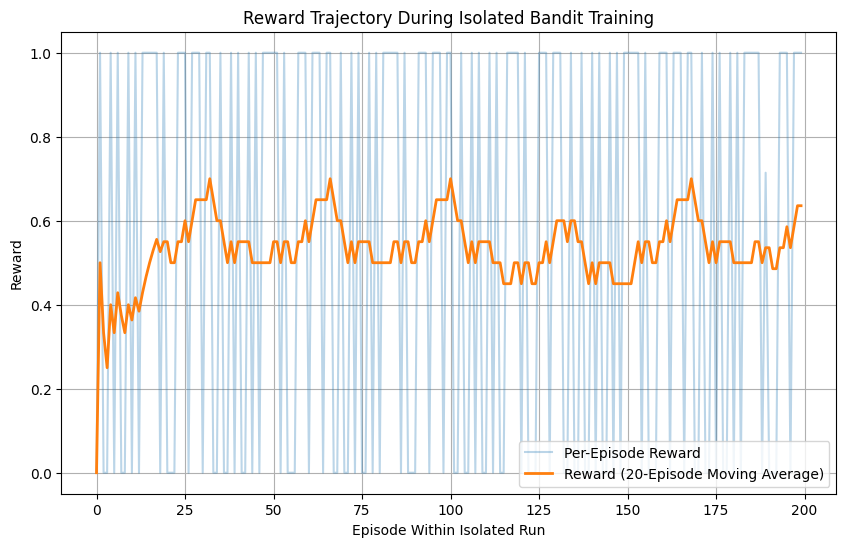

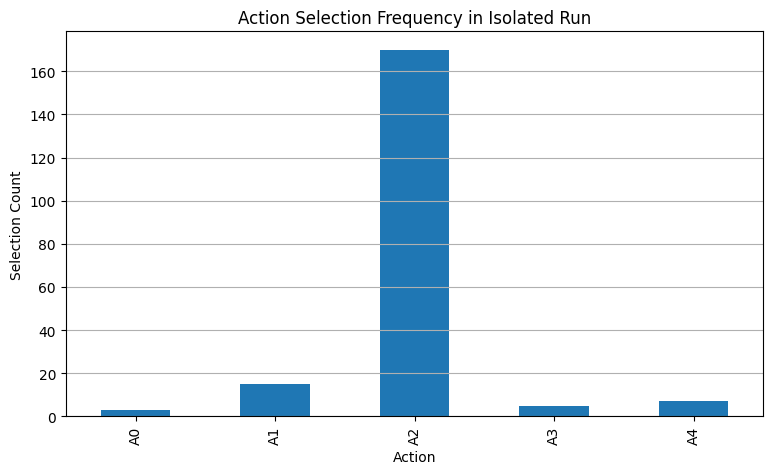

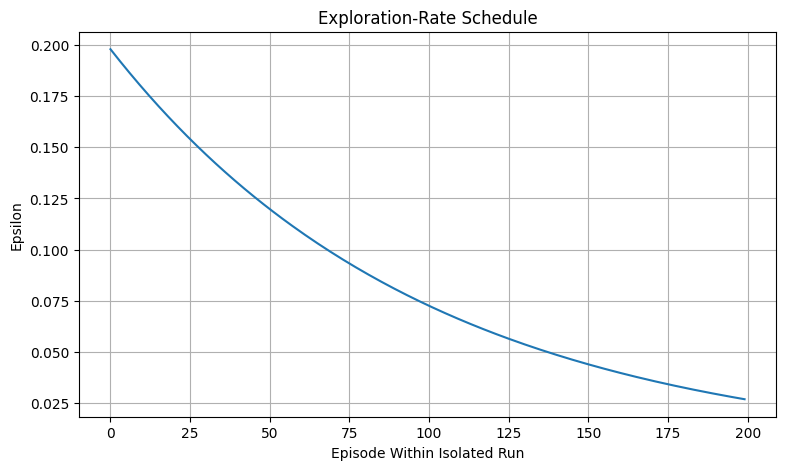

In [305]:
single_training_df = None
single_training_bandit = None
single_training_dir = None

if RUN_SINGLE_TRAINING:
    # To avoid hitting Gemini API quotas, TRAIN_EPISODES is set to 1 for this run.
    # You can increase it back to your desired value once the quota resets or is increased.
    single_training_df, single_training_bandit, single_training_dir = run_bandit_training(
        question_df=train_questions,
        num_episodes=TRAIN_EPISODES,
        seed=MASTER_SEED,
        reward_mode=DEFAULT_REWARD_MODE,
    )

    display(single_training_df.head())
    display(single_training_df.tail())

    print(single_training_bandit)
    print("Run directory:", single_training_dir)

    plot_single_run(
        single_training_df,
        out_dir=single_training_dir,
    )

    write_paper_ready_outputs(
        bandit_df=single_training_df,
        bandit=single_training_bandit,
        run_dir=single_training_dir,
    )

else:
    print("RUN_SINGLE_TRAINING is False.")

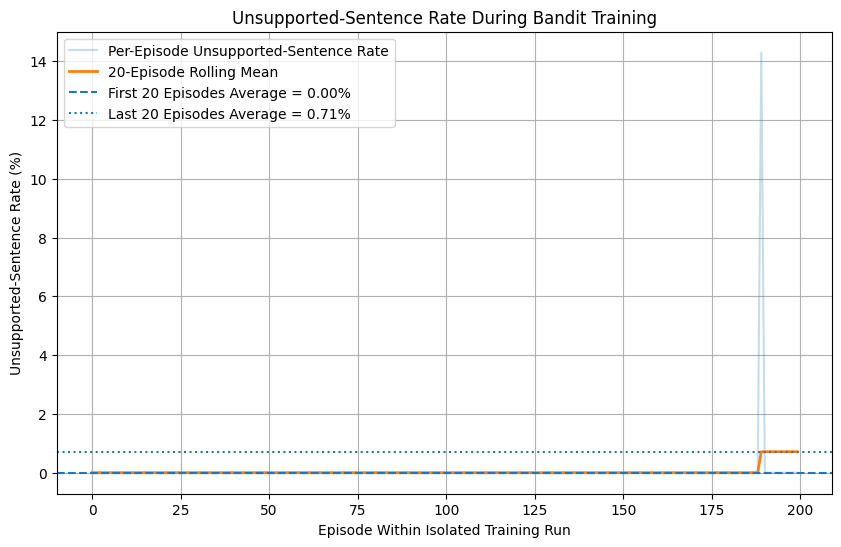

Average unsupported-sentence rate during first 20 episodes: 0.00%
Average unsupported-sentence rate during last 20 episodes: 0.71%
Absolute reduction: -0.71 percentage points
Relative reduction: nan%
Graph saved to: /content/drive/MyDrive/hallucination-penalty-rl-rag-bandit/outputs/final_runs/run_20260720_221551_187932/hallucination_proxy_curve.png


,comparison_window,early_unsupported_rate_pct,late_unsupported_rate_pct,absolute_reduction_percentage_points,relative_reduction_pct
0,20,0.0,0.714286,-0.714286,NaN


In [306]:
# ============================================================
# HALLUCINATION-PROXY REDUCTION CURVE
# ============================================================

df_hallucination = (
    single_training_df
    .sort_values("episode")
    .copy()
)

# penalty is unsupported_sentences / total_sentences
# Convert it into percentage.
df_hallucination["unsupported_rate_pct"] = (
    df_hallucination["penalty"] * 100
)

# Rolling average
window = min(
    20,
    len(df_hallucination)
)

df_hallucination["unsupported_rate_rolling_pct"] = (
    df_hallucination["unsupported_rate_pct"]
    .rolling(
        window=window,
        min_periods=1
    )
    .mean()
)

# Compare an equal-sized window at the
# beginning and end of training.
comparison_window = min(
    20,
    max(
        1,
        len(df_hallucination) // 2
    )
)

early_rate = (
    df_hallucination
    .head(comparison_window)
    ["unsupported_rate_pct"]
    .mean()
)

late_rate = (
    df_hallucination
    .tail(comparison_window)
    ["unsupported_rate_pct"]
    .mean()
)

absolute_reduction = (
    early_rate - late_rate
)

if early_rate > 0:
    relative_reduction = (
        absolute_reduction
        / early_rate
        * 100
    )
else:
    relative_reduction = float("nan")


# -------------------------
# PLOT
# -------------------------

plt.figure(
    figsize=(10, 6)
)

plt.plot(
    df_hallucination["episode"],
    df_hallucination["unsupported_rate_pct"],
    alpha=0.25,
    label="Per-Episode Unsupported-Sentence Rate"
)

plt.plot(
    df_hallucination["episode"],
    df_hallucination["unsupported_rate_rolling_pct"],
    linewidth=2,
    label=f"{window}-Episode Rolling Mean"
)

plt.axhline(
    early_rate,
    linestyle="--",
    label=(
        f"First {comparison_window} Episodes "
        f"Average = {early_rate:.2f}%"
    )
)

plt.axhline(
    late_rate,
    linestyle=":",
    label=(
        f"Last {comparison_window} Episodes "
        f"Average = {late_rate:.2f}%"
    )
)

plt.xlabel(
    "Episode Within Isolated Training Run"
)

plt.ylabel(
    "Unsupported-Sentence Rate (%)"
)

plt.title(
    "Unsupported-Sentence Rate During Bandit Training"
)

plt.legend()

plt.grid(True)

hallucination_plot_path = (
    single_training_dir
    / "hallucination_proxy_curve.png"
)

plt.savefig(
    hallucination_plot_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# -------------------------
# PRINT NUMBERS
# -------------------------

print(
    f"Average unsupported-sentence rate "
    f"during first {comparison_window} episodes: "
    f"{early_rate:.2f}%"
)

print(
    f"Average unsupported-sentence rate "
    f"during last {comparison_window} episodes: "
    f"{late_rate:.2f}%"
)

print(
    f"Absolute reduction: "
    f"{absolute_reduction:.2f} percentage points"
)

print(
    f"Relative reduction: "
    f"{relative_reduction:.2f}%"
)

print(
    f"Graph saved to: "
    f"{hallucination_plot_path}"
)


# Save numerical summary for the paper
hallucination_summary = pd.DataFrame([
    {
        "comparison_window": comparison_window,
        "early_unsupported_rate_pct": early_rate,
        "late_unsupported_rate_pct": late_rate,
        "absolute_reduction_percentage_points": absolute_reduction,
        "relative_reduction_pct": relative_reduction
    }
])

hallucination_summary.to_csv(
    single_training_dir
    / "hallucination_reduction_summary.csv",
    index=False
)

display(
    hallucination_summary
)

## 28. Run multiple independent seeds

Training run_20260720_223308_844030:   0%|          | 0/200 [00:00<?, ?it/s]

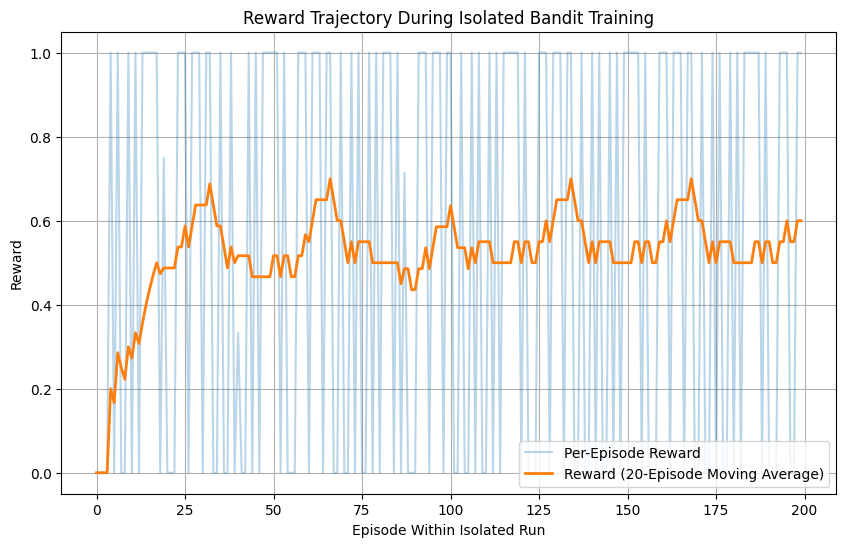

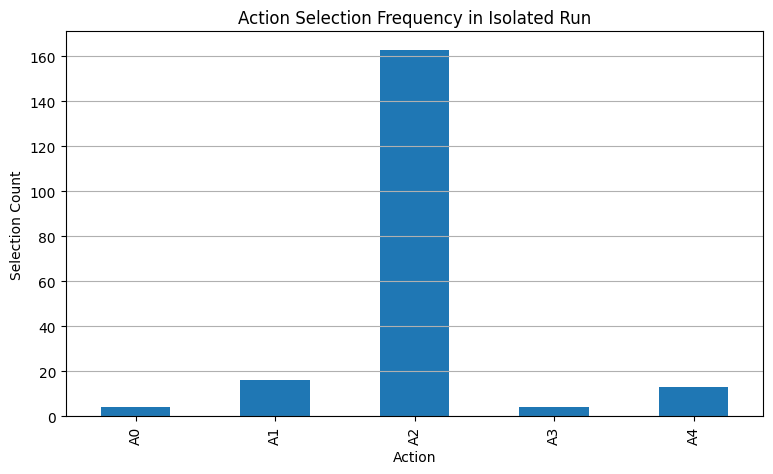

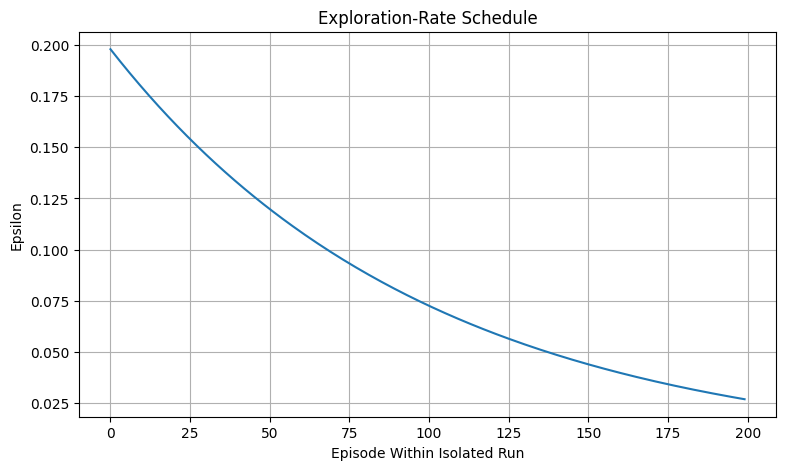

Training run_20260720_224002_632537:   0%|          | 0/200 [00:00<?, ?it/s]

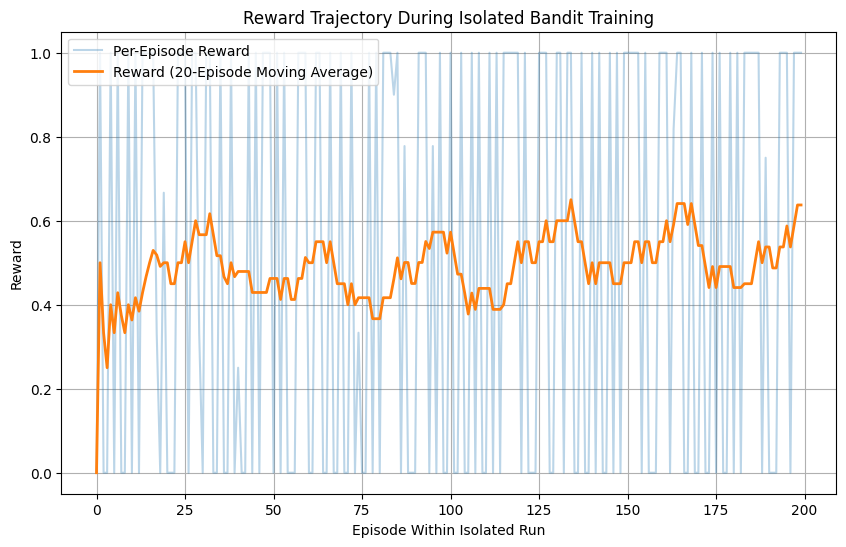

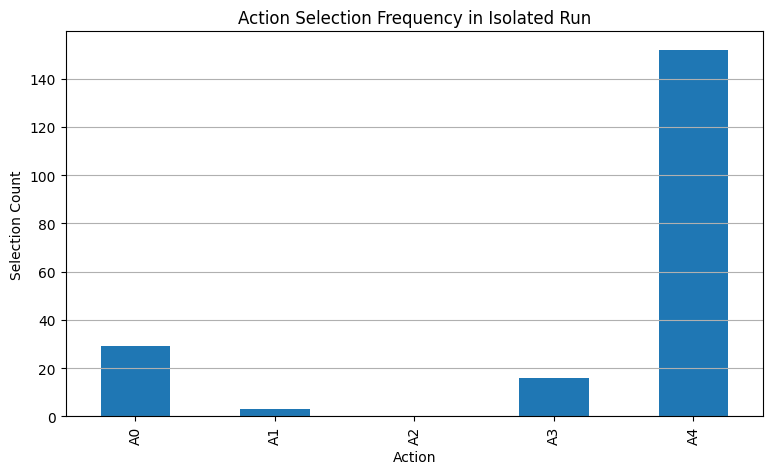

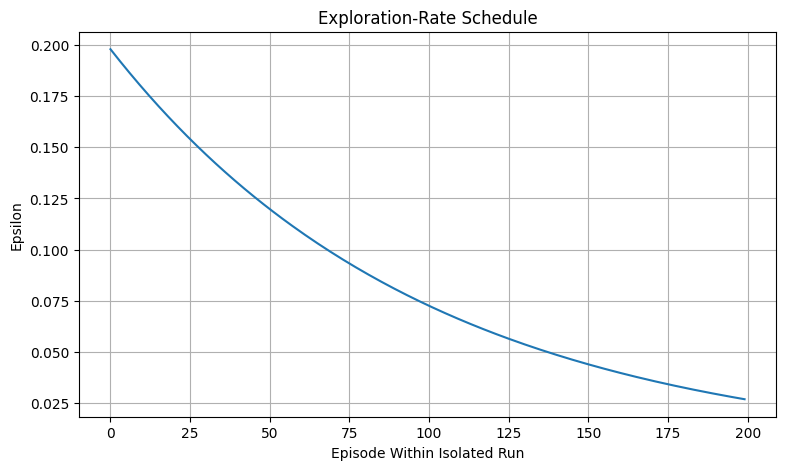

Training run_20260720_224746_058969:   0%|          | 0/200 [00:00<?, ?it/s]

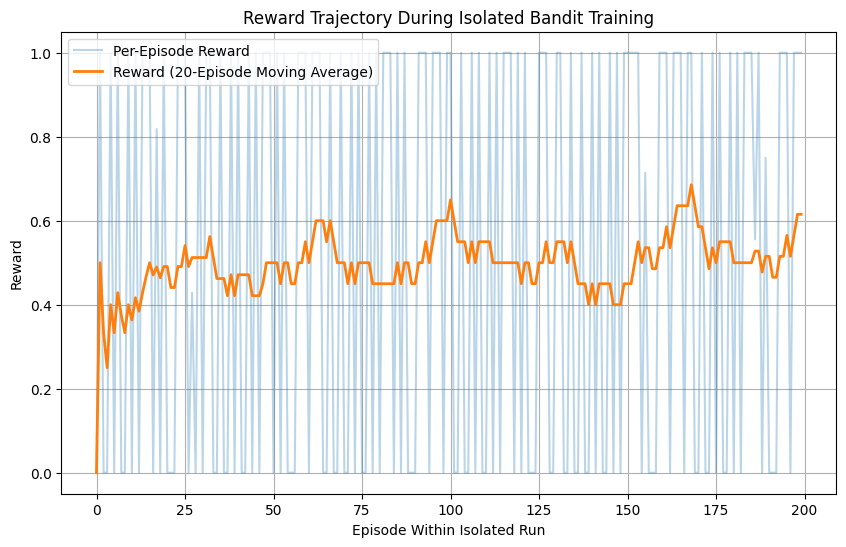

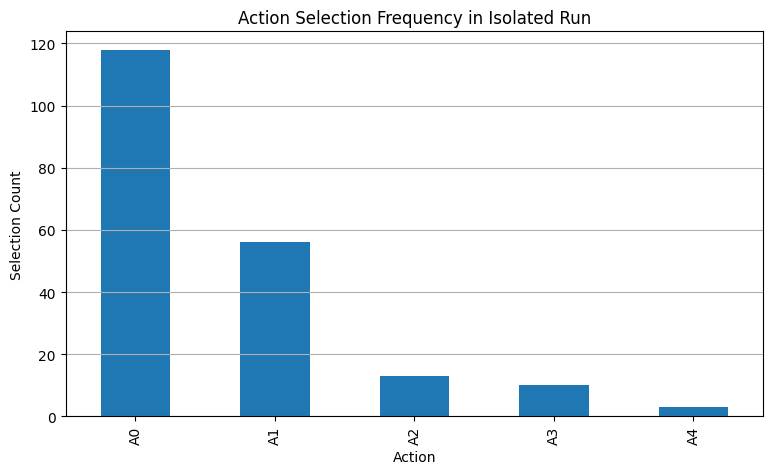

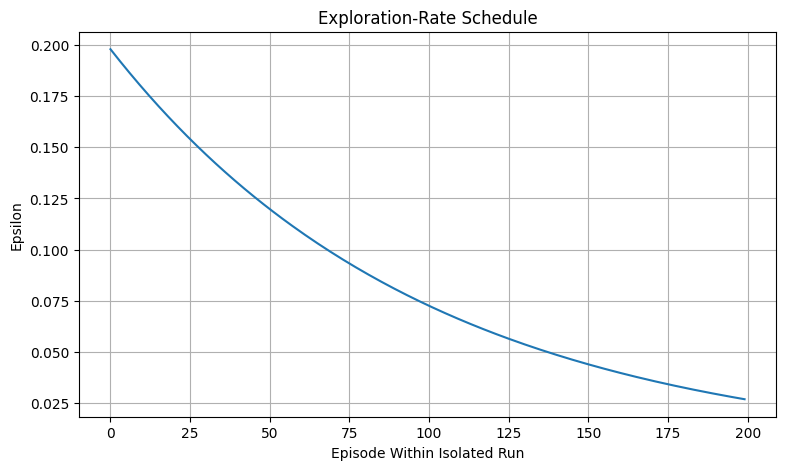

Training run_20260720_225501_107037:   0%|          | 0/200 [00:00<?, ?it/s]

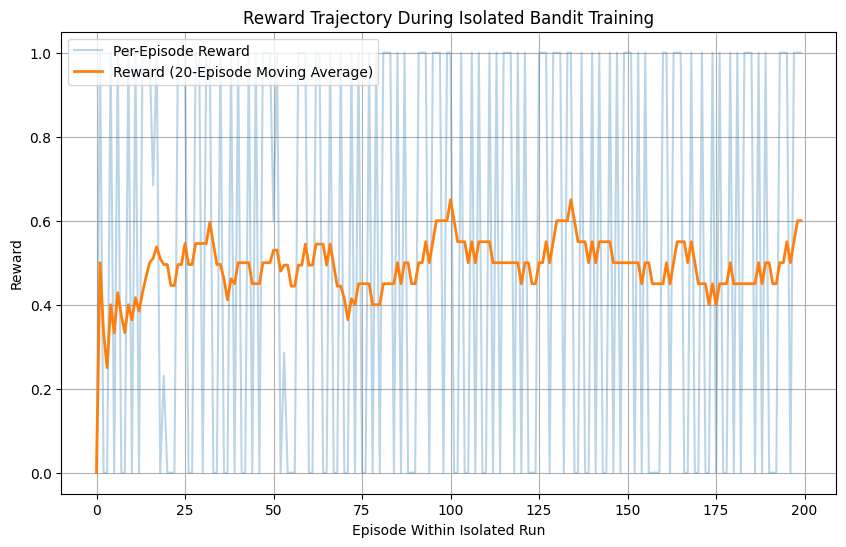

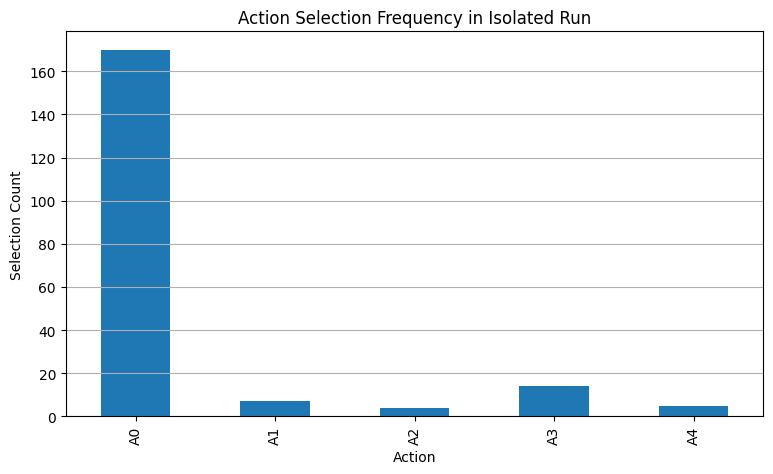

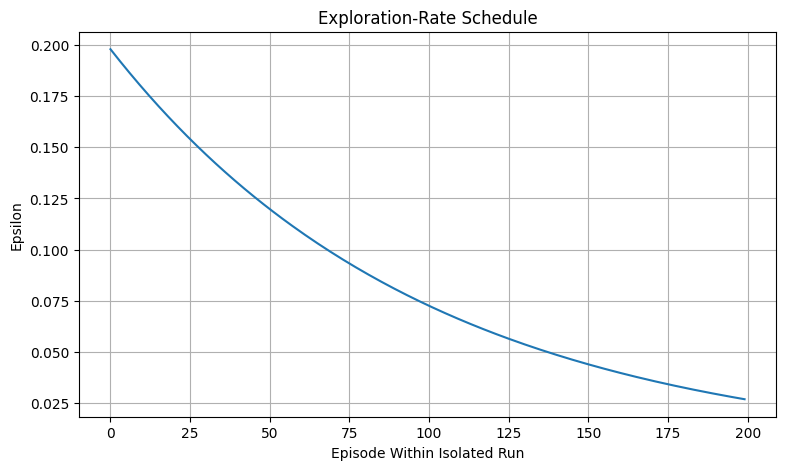

Training run_20260720_230205_344310:   0%|          | 0/200 [00:00<?, ?it/s]

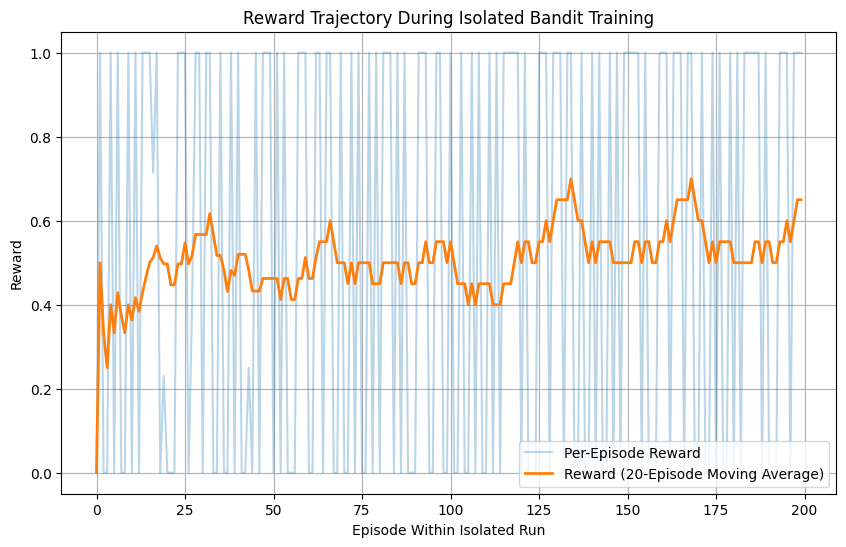

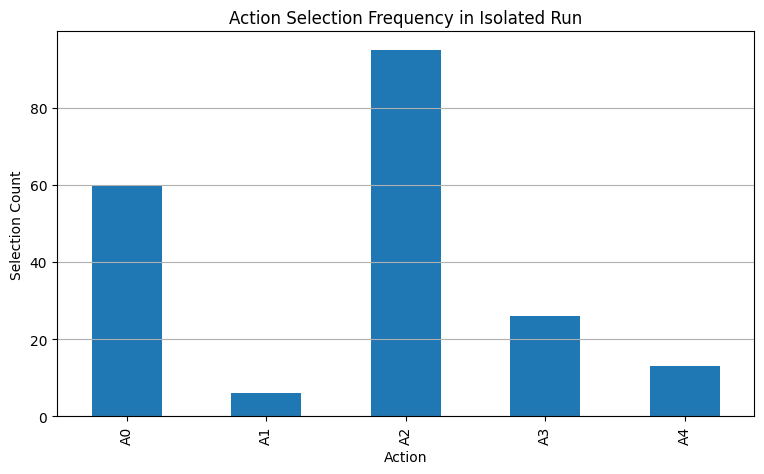

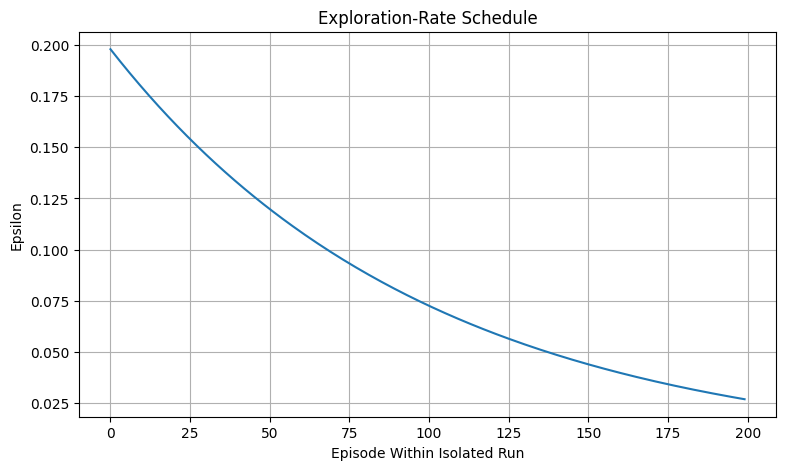

,seed,run_dir,episodes,mean_reward,final_50_mean_reward,final_epsilon,most_selected_action
0,11,/content/drive/MyDrive/hallucination-penalty-r...,200,0.538988,0.580000,0.026796,A2
1,22,/content/drive/MyDrive/hallucination-penalty-r...,200,0.504702,0.571364,0.026796,A4
2,33,/content/drive/MyDrive/hallucination-penalty-r...,200,0.511333,0.580397,0.026796,A0
3,44,/content/drive/MyDrive/hallucination-penalty-r...,200,0.504003,0.520000,0.026796,A0
4,55,/content/drive/MyDrive/hallucination-penalty-r...,200,0.522975,0.600000,0.026796,A2


In [314]:
multi_seed_summary = None

if RUN_MULTI_SEED_TRAINING:
    multi_seed_summary = run_multi_seed_training(
        question_df=train_questions,
        seeds=MULTI_SEEDS,
        episodes=TRAIN_EPISODES,
        reward_mode=DEFAULT_REWARD_MODE,
    )

    display(multi_seed_summary)

else:
    print("RUN_MULTI_SEED_TRAINING is False.")

## 29. Run fixed-policy and citation-enforced baselines on the held-out test set

In [308]:
baseline_raw_df = None
baseline_summary_df = None
baseline_run_dir = None

if RUN_BASELINES:
    baseline_raw_df, baseline_summary_df, baseline_run_dir = run_baseline_evaluation(
        question_df=test_questions,
        seed=MASTER_SEED,
        repeats=1,
        reward_mode=DEFAULT_REWARD_MODE,
    )

    display(baseline_summary_df)

    uncertainty = summarize_policy_uncertainty(
        baseline_raw_df
    )

    display(uncertainty)

    print("Baseline run directory:", baseline_run_dir)

else:
    print("RUN_BASELINES is False.")

Baselines repeat 1/1:   0%|          | 0/9 [00:00<?, ?it/s]

,policy,mean_reward,mean_groundedness,mean_citation_precision,mean_citation_coverage,mean_latency_seconds
0,Citation-Enforced-RAG,0.555556,0.555556,0.555556,1.000000,2.203990
1,Fixed-A0,0.444444,0.444444,0.444444,1.000000,1.894825
2,Fixed-A1,0.444444,0.444444,0.444444,1.000000,2.130948
3,Fixed-A2,0.555556,0.555556,0.555556,1.000000,1.955875
4,Fixed-A3,0.277778,0.416667,0.555556,0.805556,2.480022
5,Fixed-A4,0.205556,0.380556,0.444444,0.658333,2.541225
6,Uniform-Random-Expected,0.385556,NaN,NaN,NaN,NaN
7,Generate-All-Score-Max,0.555556,NaN,NaN,NaN,NaN


,policy,mean,ci_low,ci_high,n
0,Citation-Enforced-RAG,0.555556,0.222222,0.888889,9
1,Fixed-A2,0.555556,0.222222,0.888889,9
2,Fixed-A0,0.444444,0.111111,0.777778,9
3,Fixed-A1,0.444444,0.111111,0.777778,9
4,Fixed-A3,0.277778,0.000000,0.555556,9
5,Fixed-A4,0.205556,-0.194444,0.577778,9


Baseline run directory: /content/drive/MyDrive/hallucination-penalty-rl-rag-bandit/outputs/baseline_runs/baseline_20260720_222253_072604


,Policy,Unsupported-Sentence Rate (%)
0,Fixed-A0,0.000000
1,Fixed-A1,0.000000
2,Fixed-A2,0.000000
3,Citation-Enforced RAG,0.000000
4,Bandit Greedy Policy (A2),0.000000
5,Generate-All + Score-Max,0.000000
6,Uniform Random,6.277778
7,Fixed-A3,13.888889
8,Fixed-A4,17.500000


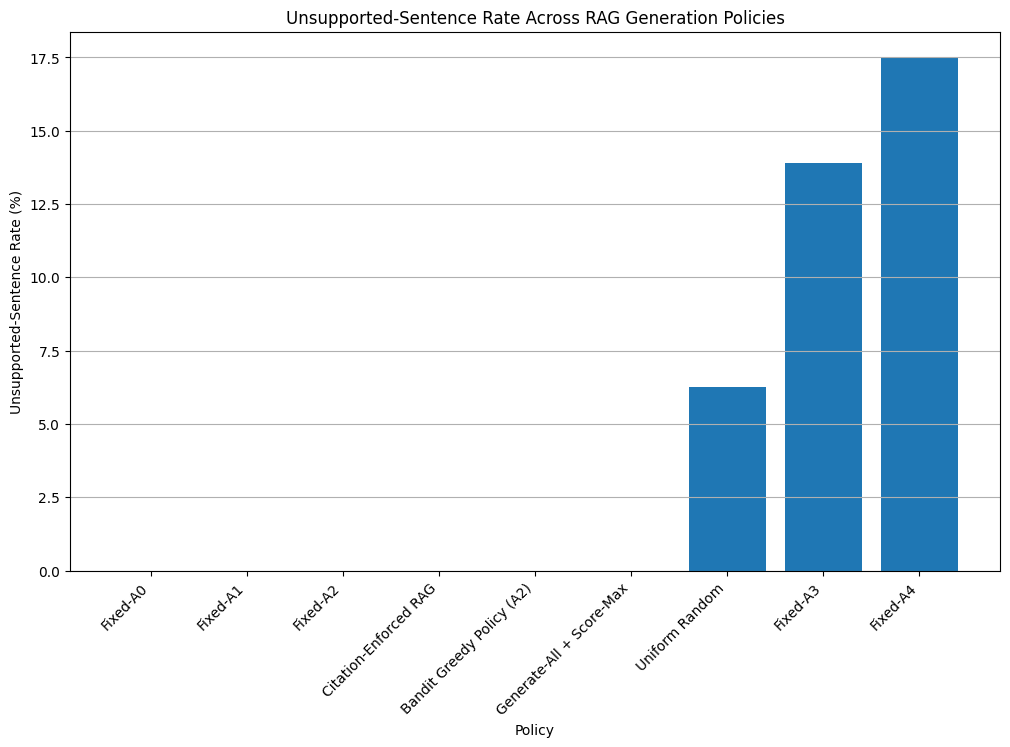

Saved: /content/drive/MyDrive/hallucination-penalty-rl-rag-bandit/outputs/baseline_runs/baseline_20260720_222253_072604/hallucination_proxy_policy_comparison.png
Learned greedy action: A2
Uniform-random unsupported rate: 6.28%
Bandit-greedy unsupported rate: 0.00%
Relative reduction versus uniform random: 100.00%


In [309]:
# ============================================================
# HALLUCINATION-PROXY COMPARISON ACROSS POLICIES
# ============================================================

# Only the fixed A0-A4 strategies
fixed_policies = [
    f"Fixed-{action}"
    for action in ACTIONS
]

fixed_df = baseline_raw_df[
    baseline_raw_df["policy"]
    .isin(fixed_policies)
].copy()


# ------------------------------------------------------------
# Mean unsupported-sentence rate for every fixed strategy
# ------------------------------------------------------------

policy_hallucination = (
    fixed_df
    .groupby("policy")
    ["penalty"]
    .mean()
    * 100
)


# ------------------------------------------------------------
# Citation-enforced baseline
# ------------------------------------------------------------

citation_rows = baseline_raw_df[
    baseline_raw_df["policy"]
    == "Citation-Enforced-RAG"
]

if not citation_rows.empty:
    citation_rate = (
        citation_rows["penalty"]
        .mean()
        * 100
    )
else:
    citation_rate = float("nan")


# ------------------------------------------------------------
# Expected uniform-random hallucination rate
#
# For every question, randomly selecting among A0-A4 has
# expected penalty equal to the mean penalty of those actions.
# ------------------------------------------------------------

random_rate = (
    fixed_df
    .groupby(
        [
            "repeat",
            "question_id"
        ]
    )
    ["penalty"]
    .mean()
    .mean()
    * 100
)


# ------------------------------------------------------------
# Bandit's final greedy strategy
#
# Since the current bandit is non-contextual,
# its learned deployment policy is the arm with maximum Q.
# ------------------------------------------------------------

learned_action = max(
    single_training_bandit.q_values,
    key=single_training_bandit.q_values.get
)

learned_policy_name = (
    f"Fixed-{learned_action}"
)

learned_rows = baseline_raw_df[
    baseline_raw_df["policy"]
    == learned_policy_name
]

learned_rate = (
    learned_rows["penalty"]
    .mean()
    * 100
)


# ------------------------------------------------------------
# Generate-All + Score-Max
#
# Select the candidate with maximum reward for each question,
# then examine the penalty of that selected candidate.
# ------------------------------------------------------------

best_candidate_indices = (
    fixed_df
    .groupby(
        [
            "repeat",
            "question_id"
        ]
    )
    ["reward"]
    .idxmax()
)

score_max_rate = (
    fixed_df
    .loc[
        best_candidate_indices,
        "penalty"
    ]
    .mean()
    * 100
)


# ------------------------------------------------------------
# Build comparison table
# ------------------------------------------------------------

comparison_rows = []

for policy, rate in policy_hallucination.items():
    comparison_rows.append({
        "Policy": policy,
        "Unsupported-Sentence Rate (%)": rate
    })

comparison_rows.append({
    "Policy": "Uniform Random",
    "Unsupported-Sentence Rate (%)": random_rate
})

comparison_rows.append({
    "Policy": (
        f"Bandit Greedy Policy "
        f"({learned_action})"
    ),
    "Unsupported-Sentence Rate (%)": learned_rate
})

comparison_rows.append({
    "Policy": "Citation-Enforced RAG",
    "Unsupported-Sentence Rate (%)": citation_rate
})

comparison_rows.append({
    "Policy": "Generate-All + Score-Max",
    "Unsupported-Sentence Rate (%)": score_max_rate
})


comparison_df = pd.DataFrame(
    comparison_rows
)

comparison_df = (
    comparison_df
    .dropna()
    .sort_values(
        "Unsupported-Sentence Rate (%)"
    )
    .reset_index(drop=True)
)

display(
    comparison_df
)


# ------------------------------------------------------------
# Plot
# ------------------------------------------------------------

plt.figure(
    figsize=(12, 7)
)

plt.bar(
    comparison_df["Policy"],
    comparison_df[
        "Unsupported-Sentence Rate (%)"
    ]
)

plt.ylabel(
    "Unsupported-Sentence Rate (%)"
)

plt.xlabel(
    "Policy"
)

plt.title(
    "Unsupported-Sentence Rate Across RAG Generation Policies"
)

plt.xticks(
    rotation=45,
    ha="right"
)

plt.grid(
    axis="y"
)

comparison_plot_path = (
    baseline_run_dir
    / "hallucination_proxy_policy_comparison.png"
)

plt.savefig(
    comparison_plot_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(
    "Saved:",
    comparison_plot_path
)


# ------------------------------------------------------------
# Reduction compared with uniform random policy
# ------------------------------------------------------------

if random_rate > 0:

    reduction_vs_random = (
        (
            random_rate
            - learned_rate
        )
        / random_rate
        * 100
    )

    print(
        f"Learned greedy action: "
        f"{learned_action}"
    )

    print(
        f"Uniform-random unsupported rate: "
        f"{random_rate:.2f}%"
    )

    print(
        f"Bandit-greedy unsupported rate: "
        f"{learned_rate:.2f}%"
    )

    print(
        f"Relative reduction versus "
        f"uniform random: "
        f"{reduction_vs_random:.2f}%"
    )

## 30. Controlled-temperature ablation

This helps separate prompt-strategy effects from temperature effects by evaluating all strategies at the same temperature.

In [310]:
controlled_temp_raw = None
controlled_temp_summary = None

if RUN_CONTROLLED_TEMP_ABLATION:
    controlled_temp_raw, controlled_temp_summary, controlled_temp_dir = run_baseline_evaluation(
        question_df=test_questions,
        seed=MASTER_SEED,
        repeats=1,
        reward_mode=DEFAULT_REWARD_MODE,
        controlled_temperature=CONTROLLED_TEMPERATURE,
    )

    display(controlled_temp_summary)
    print("Controlled-temperature run:", controlled_temp_dir)

else:
    print("RUN_CONTROLLED_TEMP_ABLATION is False.")

RUN_CONTROLLED_TEMP_ABLATION is False.


## 31. Threshold calibration

Only enable this after creating a human-labelled validation file with:

- `sentence`
- `context`
- `human_supported`

In [311]:
THRESHOLD_ANNOTATION_CSV = ANNOTATION_DIR / "threshold_validation.csv"

if RUN_THRESHOLD_CALIBRATION:
    if not THRESHOLD_ANNOTATION_CSV.exists():
        raise FileNotFoundError(
            f"Missing threshold annotation file: {THRESHOLD_ANNOTATION_CSV}"
        )

    threshold_annotations = pd.read_csv(
        THRESHOLD_ANNOTATION_CSV
    )

    threshold_results = calibrate_similarity_threshold(
        threshold_annotations
    )

    display(threshold_results)

    threshold_results.to_csv(
        ANNOTATION_DIR / "threshold_calibration_results.csv",
        index=False,
    )

else:
    print("RUN_THRESHOLD_CALIBRATION is False.")

RUN_THRESHOLD_CALIBRATION is False.


## 32. Retrieval demo

This is a non-training smoke test.

In [312]:
DEMO_QUERY = "What is Retrieval-Augmented Generation?"

try:
    contexts, sources, hits = retrieve(
        DEMO_QUERY,
        top_k=DEFAULT_TOP_K,
        require_nontrivial_corpus=False,
    )

    display(pd.DataFrame([
        {
            "source_id": h["source_id"],
            "score": h["score"],
            "text_preview": h["text"][:200],
        }
        for h in hits
    ]))

except Exception as exc:
    print("Retrieval demo could not run:", exc)

,source_id,score,text_preview
0,rag_basics.txt#0,0.478938,Retrieval-Augmented Generation (RAG) is a tech...
1,Deep_reinforcement_learning.txt#11,0.418729,=== Goal-conditioned reinforcement learning ==...
2,Deep_reinforcement_learning.txt#9,0.413102,== Research == Deep reinforcement learning is ...
3,Augmented_Analytics.txt#0,0.379121,Augmented Analytics is an approach of data ana...
4,AI_alignment.txt#19,0.374759,"Another approach is to train a helper model (""..."


## 33. Final experiment checklist

---



Before using any results in the camera-ready paper, verify all of the following:

- [ ] The run directory contains `RUN_COMPLETE.json`.
- [ ] There is exactly one `run_id` in the training CSV.
- [ ] Episode numbers are unique within the run.
- [ ] No old `bandit_state.json` was loaded.
- [ ] The bandit chose an action before generation.
- [ ] Only the selected arm updated the bandit.
- [ ] API failures produced no reward observations.
- [ ] Final epsilon matches the configured decay schedule.
- [ ] The final corpus contains substantially more chunks than `top_k`.
- [ ] Training, validation, and test questions are separated.
- [ ] Fixed A0–A4 baselines are reported.
- [ ] Citation-enforced RAG is reported.
- [ ] Generate-all + score-max is reported separately.
- [ ] Human factual-support annotation has been performed on a subset.
- [ ] The automatic reward has been compared with human judgment.
- [ ] Similarity threshold selection is documented.
- [ ] At least several independent seeds are reported.
- [ ] Confidence intervals / uncertainty are reported.
- [ ] Every paper figure is regenerated from one clearly identified run.
- [ ] The paper no longer describes multiple appended development sessions as one learning trajectory.

## Relationship to the remaining paper corrections

This notebook fixes or provides infrastructure for many implementation issues beyond Point 5.  
However, **paper text still has to be revised separately**, especially Point 2A and Point 6 onward, which the author has not yet manually reviewed.

## 34. Validation of Automatic Hallucination/Support Metric

In [316]:
# ============================================================
# HUMAN VALIDATION DATASET FOR AUTOMATIC SUPPORT METRIC
# ============================================================

from sklearn.metrics import (
    cohen_kappa_score,
    accuracy_score,
    precision_recall_fscore_support,
    confusion_matrix
)

VALIDATION_DIR = (
    ANNOTATION_DIR
    / "metric_validation"
)

VALIDATION_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# ============================================================
# FIND THE MOST RECENT COMPLETED BASELINE RUN
# ============================================================

completed_baseline_dirs = []

for run_dir in BASELINE_RUNS_DIR.glob(
    "baseline_*"
):

    if (
        run_dir
        / "RUN_COMPLETE.json"
    ).exists():

        if (
            run_dir
            / "baseline_raw.csv"
        ).exists():

            completed_baseline_dirs.append(
                run_dir
            )


if not completed_baseline_dirs:

    raise FileNotFoundError(
        "No completed baseline run was found."
    )


latest_baseline_dir = max(

    completed_baseline_dirs,

    key=lambda path:
        path.stat().st_mtime

)


baseline_csv = (

    latest_baseline_dir

    / "baseline_raw.csv"

)


print(
    "Using baseline data:"
)

print(
    baseline_csv
)


baseline_validation_df = pd.read_csv(
    baseline_csv
)


print(
    "Baseline responses:",
    len(
        baseline_validation_df
    )
)


# ============================================================
# LOAD CHUNK METADATA
# ============================================================

chunk_metadata = safe_read_json(
    METADATA_JSON,
    []
)


source_lookup = {}


for item in chunk_metadata:

    source_id = item.get(
        "source_id"
    )

    if not source_id:

        source_id = canonical_source_id(

            item.get(
                "doc_name",
                "unknown"
            ),

            item.get(
                "chunk_id",
                "?"
            )

        )

    source_lookup[
        source_id
    ] = item


print(
    "Indexed source chunks:",
    len(
        source_lookup
    )
)


# ============================================================
# LOAD SAME EMBEDDING MODEL USED BY REWARD FUNCTION
# ============================================================

scoring_model = get_scoring_model()


validation_rows = []


sample_counter = 1


# ============================================================
# CREATE ONE VALIDATION ROW PER GENERATED SENTENCE
# ============================================================

for row_index, row in baseline_validation_df.iterrows():

    answer = str(
        row[
            "answer"
        ]
    ).strip()


    # We validate factual sentence support separately.
    # Abstention validation is a different task.
    if is_strict_abstention(
        answer
    ):

        continue


    try:

        sources = json.loads(
            row[
                "sources"
            ]
        )

    except Exception:

        sources = []


    # --------------------------------------------------------
    # RECONSTRUCT RETRIEVED CONTEXT
    # --------------------------------------------------------

    context_blocks = []


    for source_id in sources:

        metadata = source_lookup.get(
            source_id
        )


        if metadata:

            context_blocks.append(

                (
                    f"[source: {source_id}]\n"
                    f"{metadata.get('text', '')}"
                )

            )


    retrieved_context = (
        "\n\n".join(
            context_blocks
        )
    )


    if not retrieved_context.strip():

        continue


    context_sentences = sentence_split(
        retrieved_context
    )


    answer_sentences = sentence_split(
        answer
    )


    if (
        not context_sentences
        or
        not answer_sentences
    ):

        continue


    # --------------------------------------------------------
    # COMPUTE THE SAME SEMANTIC SIMILARITY USED BY YOUR METRIC
    # --------------------------------------------------------

    context_embeddings = np.asarray(

        scoring_model.encode(

            context_sentences,

            normalize_embeddings=True

        ),

        dtype="float32"

    )


    answer_embeddings = np.asarray(

        scoring_model.encode(

            answer_sentences,

            normalize_embeddings=True

        ),

        dtype="float32"

    )


    similarity_matrix = (

        answer_embeddings

        @

        context_embeddings.T

    )


    answer_uid = (

        str(
            row[
                "question_id"
            ]
        )

        + "__"

        + str(
            row[
                "policy"
            ]
        )

        + "__"

        + str(
            row.get(
                "repeat",
                0
            )
        )

    )


    for sentence_index, sentence in enumerate(
        answer_sentences
    ):


        max_similarity = float(

            similarity_matrix[

                sentence_index

            ].max()

        )


        automatic_supported = int(

            max_similarity

            >=

            DEFAULT_SENT_SIM_THRESHOLD

        )


        # Remove citation tags only from the version
        # displayed to human annotators.
        clean_sentence = CITATION_RE.sub(

            "",

            sentence

        ).strip()


        validation_rows.append({

            "sample_id":
                f"S{sample_counter:04d}",

            "answer_uid":
                answer_uid,

            "question_id":
                row[
                    "question_id"
                ],

            "question":
                row[
                    "question"
                ],

            "policy":
                row[
                    "policy"
                ],

            "full_answer":
                answer,

            "sentence_raw":
                sentence,

            "sentence_for_annotation":
                clean_sentence,

            "retrieved_context":
                retrieved_context,

            "auto_max_similarity":
                max_similarity,

            "auto_supported":
                automatic_supported,

            "threshold":
                DEFAULT_SENT_SIM_THRESHOLD

        })


        sample_counter += 1


validation_key_df = pd.DataFrame(
    validation_rows
)


if validation_key_df.empty:

    raise RuntimeError(
        "No validation sentences were generated."
    )


# ============================================================
# SHUFFLE SO HUMAN ANNOTATORS DO NOT SEE POLICY GROUPINGS
# ============================================================

validation_key_df = (

    validation_key_df

    .sample(

        frac=1,

        random_state=42

    )

    .reset_index(
        drop=True
    )

)


# ============================================================
# SAVE PRIVATE AUTOMATIC-METRIC KEY
# ============================================================

key_path = (

    VALIDATION_DIR

    / "human_validation_key.csv"

)


validation_key_df.to_csv(

    key_path,

    index=False

)


# ============================================================
# CREATE BLINDED HUMAN ANNOTATION SHEETS
#
# Important:
# Policy and automatic scores are intentionally hidden.
# ============================================================

blinded_columns = [

    "sample_id",

    "question",

    "sentence_for_annotation",

    "full_answer",

    "retrieved_context"

]


blinded_df = validation_key_df[

    blinded_columns

].copy()


blinded_df[
    "human_label"
] = ""


annotator_1_path = (

    VALIDATION_DIR

    / "annotator_1.csv"

)


annotator_2_path = (

    VALIDATION_DIR

    / "annotator_2.csv"

)


blinded_df.to_csv(

    annotator_1_path,

    index=False

)


blinded_df.to_csv(

    annotator_2_path,

    index=False

)


print(
    "\nHuman validation dataset created."
)


print(
    "\nTotal factual sentences to annotate:",
    len(
        blinded_df
    )
)


print(
    "\nAnnotator 1 file:"
)

print(
    annotator_1_path
)


print(
    "\nAnnotator 2 file:"
)

print(
    annotator_2_path
)


print(
    "\nPrivate automatic-metric key:"
)

print(
    key_path
)


display(

    blinded_df.head()

)

Using baseline data:
/content/drive/MyDrive/hallucination-penalty-rl-rag-bandit/outputs/baseline_runs/baseline_20260720_222253_072604/baseline_raw.csv
Baseline responses: 54
Indexed source chunks: 1245

Human validation dataset created.

Total factual sentences to annotate: 64

Annotator 1 file:
/content/drive/MyDrive/hallucination-penalty-rl-rag-bandit/outputs/human_annotation/metric_validation/annotator_1.csv

Annotator 2 file:
/content/drive/MyDrive/hallucination-penalty-rl-rag-bandit/outputs/human_annotation/metric_validation/annotator_2.csv

Private automatic-metric key:
/content/drive/MyDrive/hallucination-penalty-rl-rag-bandit/outputs/human_annotation/metric_validation/human_validation_key.csv


[Public-release sanitization: text-bearing corpus output removed.]

## Final non-LaTeX correction layer (semantic scorer v2)

This layer imports the versioned scoring-specific unit extractor, substantive-unit citation coverage, and context-conditioned NLI evaluator. Historical output folders remain frozen. Expensive run switches remain disabled.


In [ ]:
# Corrected final revision layer; human/AI annotation and manuscript workflows are excluded.
from scoring.reward import (
    extract_scoring_units, is_pure_formatting_unit, is_strict_abstention,
    citation_metrics, semantic_support_score_legacy_v1, semantic_support_score_v2,
)
from scoring.nli import nli_support_score

semantic_support_score = semantic_support_score_v2
SEMANTIC_SCORER_VERSION = "semantic_proxy_clean_v2"
FINAL_REVISION_OUTPUT_DIR = OUTPUTS_DIR / "final_revision_nonlatex"
FINAL_EXPERIMENT_MODE = True

# Deliberately prevent expensive/API work from rerunning on notebook open.
RUN_INGEST = False
RUN_BUILD_INDEX = False
RUN_SINGLE_TRAINING = False
RUN_MULTI_SEED_TRAINING = False
RUN_BASELINES = False
RUN_CONTROLLED_TEMP_ABLATION = False
RUN_THRESHOLD_CALIBRATION = False
print("Corrected scorer v2 and context-conditioned NLI definitions active.")
